<a href="https://colab.research.google.com/github/knguyen-spec/diabetes-prediction-Oct26/blob/main/FINALdiabetes_130_hospitals_group3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Readmission of Diabetic Patients in the USA (under 30 days)

Dataset used: Option 3, Diabetes 130-US Hospitals

*Beata Strack, Jonathan P. DeShazo, Chris Gennings, Juan L. Olmo, Sebastian Ventura, Krzysztof J. Cios, and John N. Clore, “Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records,” BioMed Research International, vol. 2014, Article ID 781670, 11 pages, 2014.*

# Prerequisites

In [ ]:
%pip install -q lightgbm optuna mlflow shap imbalanced-learn cloudpickle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from IPython.display import display

# Hide a harmless LightGBM warning about feature names.
import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")

RANDOM_STATE = 42  # to get the same results at every run

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 150)

In [ ]:
# Option 3 -- Diabetes 130 Hospitals (OpenML id 4541)
diabetes = fetch_openml(data_id=4541, as_frame=True)
X, y = diabetes.data, diabetes.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (101766, 49)
Shape of y: (101766,)


The dataset has 10 years (1999–2008) of records from 130 US hospitals. Each row is one hospital stay of a diabetic patient. The columns describe the patient (age, race, gender), the stay (length, lab tests, medications), the history (visits in the past year) and the diabetes treatment.

**Goal:** predict if a patient will come back to the hospital within 30 days after leaving it.

As hospital managers, we could then offer extra follow-up to the patients at risk, and plan beds and staff.

The original target `readmitted` has 3 values: "NO" (never readmitted), ">30" (after more than 30 days) and "<30" (within 30 days).

# EDA & Problem Framing

In [ ]:
# Convert the "category" columns to text (easier to handle).
X = X.copy()
for col in X.select_dtypes("category").columns:
    X[col] = X[col].astype(object)

# Missing values are sometimes written "?" in this dataset.
X = X.replace("?", np.nan)

# One table with the features and the original target (3 classes).
y = y.copy().rename("readmitted")
df = pd.concat([X, y], axis=1)

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


First look at the data: size, types, missing values, duplicates.

In [ ]:
print({"Number of rows": df.shape[0]})
print({"Number of columns": df.shape[1]})
print({"Number of missing values": int(df.isna().sum().sum())})
print({"Number of duplicates": int(df.duplicated().sum())})

{'Number of rows': 101766}
{'Number of columns': 50}
{'Number of missing values': 192849}
{'Number of duplicates': 0}


In [ ]:
# Column types, number of distinct values and one example per column.
print("Data types:")
print(df.dtypes.value_counts())
print()
df_info = pd.DataFrame(
    {"Pandas Dtype": df.dtypes,
     "Unique Values": df.nunique(),
     "Sample Value": df.iloc[0],})
print(df_info)

Data types:
object      36
int64       13
category     1
Name: count, dtype: int64

                         Pandas Dtype  Unique Values              Sample Value
encounter_id                    int64         101766                   2278392
patient_nbr                     int64          71518                   8222157
race                           object              5                 Caucasian
gender                         object              3                    Female
age                            object             10                    [0-10)
weight                         object              9                       NaN
admission_type_id               int64              8                         6
discharge_disposition_id        int64             26                        25
admission_source_id             int64             17                         1
time_in_hospital                int64             14                         1
payer_code                     object          

                   n_missing  pct_missing
weight                 98569        96.86
medical_specialty      49949        49.08
payer_code             40256        39.56
race                    2273         2.23
diag_3                  1423         1.40
diag_2                   358         0.35
diag_1                    21         0.02


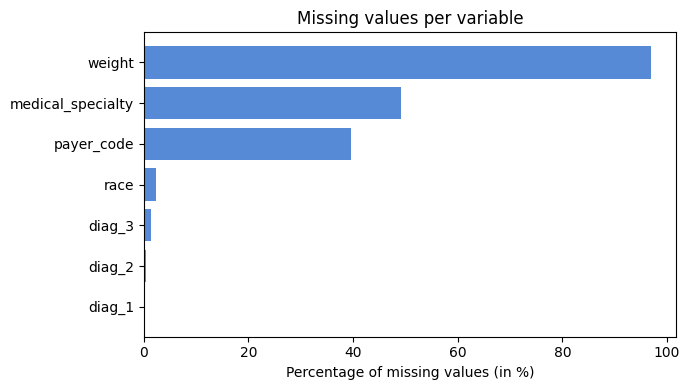

In [ ]:
# Number and percentage of missing values per column.
n_missing = df.isna().sum()
missing = pd.DataFrame({
    "n_missing": n_missing,
    "pct_missing": (100 * n_missing / len(df)).round(2),})
missing = missing[missing["n_missing"] > 0].sort_values("pct_missing", ascending=False)
print(missing)

plt.figure(figsize=(7, 4))
plt.barh(missing.index[::-1], missing["pct_missing"][::-1], color="#578AD6")
plt.xlabel("Percentage of missing values (in %)")
plt.title("Missing values per variable")
plt.tight_layout()
plt.show()

In [ ]:
# The identifiers and the *_id codes are stored as numbers but are not real quantities.
id_cols = ["encounter_id", "patient_nbr"]
coded_cols = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

num_cols = [c for c in df.select_dtypes("number").columns
            if c not in id_cols + coded_cols]

print("Numerical variables:", num_cols)
df[num_cols].describe().T

Numerical variables: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


In [ ]:
# Number of levels of each categorical column.
cat_cols = [c for c in df.columns
            if c not in num_cols + id_cols + ["readmitted"]]
n_modalities = df[cat_cols].nunique().sort_values(ascending=False)

print(n_modalities)

diag_3                      789
diag_2                      748
diag_1                      716
medical_specialty            72
discharge_disposition_id     26
admission_source_id          17
payer_code                   17
age                          10
weight                        9
admission_type_id             8
race                          5
glyburide.metformin           4
max_glu_serum                 4
A1Cresult                     4
metformin                     4
repaglinide                   4
nateglinide                   4
chlorpropamide                4
glimepiride                   4
glipizide                     4
glyburide                     4
rosiglitazone                 4
pioglitazone                  4
acarbose                      4
insulin                       4
miglitol                      4
gender                        3
tolazamide                    3
acetohexamide                 2
tolbutamide                   2
troglitazone                  2
metformi

In [ ]:
# Quasi-constant columns: one value covers more than 99% of the rows.
top_share = df[cat_cols + num_cols].apply(
    lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
print("Quasi-constant variables:")
print(top_share[top_share > 0.99].round(4))
print()

for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} different codes")

Quasi-constant variables:
nateglinide                 0.9931
chlorpropamide              0.9992
acetohexamide               1.0000
tolbutamide                 0.9998
acarbose                    0.9970
miglitol                    0.9996
troglitazone                1.0000
tolazamide                  0.9996
examide                     1.0000
citoglipton                 1.0000
glyburide.metformin         0.9931
glipizide.metformin         0.9999
glimepiride.pioglitazone    1.0000
metformin.rosiglitazone     1.0000
metformin.pioglitazone      1.0000
dtype: float64

admission_type_id: 8 different codes
discharge_disposition_id: 26 different codes
admission_source_id: 17 different codes


In [ ]:
# Discharge codes for death (11, 19, 20, 21) or hospice (13, 14).
death_hospice_codes = [11, 13, 14, 19, 20, 21]
discharge = pd.to_numeric(df["discharge_disposition_id"], errors="coerce")
is_death_hospice = discharge.isin(death_hospice_codes)
print(f"\nStays ending in death / hospice: {is_death_hospice.sum()} "
      f"({is_death_hospice.mean():.1%})")
print("Their <30-day readmission rate:",
      f"{(df.loc[is_death_hospice, 'readmitted'] == '<30').mean():.2%}")
print()

# The same patient can have several stays.
per_patient = df.groupby("patient_nbr").size()
print(f"\nNumber of stays: {len(df)} | number of patients: {len(per_patient)}")
print(f"Patients with several stays: {(per_patient > 1).mean():.1%}")
print()

print("Duplicated rows:", df.duplicated().sum())


Stays ending in death / hospice: 2423 (2.4%)
Their <30-day readmission rate: 1.77%


Number of stays: 101766 | number of patients: 71518
Patients with several stays: 23.5%

Duplicated rows: 0


**What we learn**

- `weight` is missing in 96.9% of the rows: we drop it.
- `medical_specialty` (49.1% missing) and `payer_code` (39.6%) are often empty. We keep them and use "Missing" as a category. `race` is missing in 2.2% of the rows.
- The `*_id` columns are codes stored as numbers, so we treat them as categories (Session 1).
- 15 medication columns have one value in more than 99% of the rows (`examide` and `citoglipton` have only one value). We keep them; the encoder groups rare values anyway.
- 2,423 stays (2.4%) end in death or hospice. These patients cannot get a follow-up, so we remove them (1.8% of them are still labelled "<30", probably hospice patients).
- 23.5% of the patients have several stays. To avoid group leakage (Session 1), all the stays of a patient must be on the same side of the split.

Now the target: how rare is a readmission within 30 days?

readmitted
NO     53.91 %
>30    34.93 %
<30    11.16 %
Name: count, dtype: object


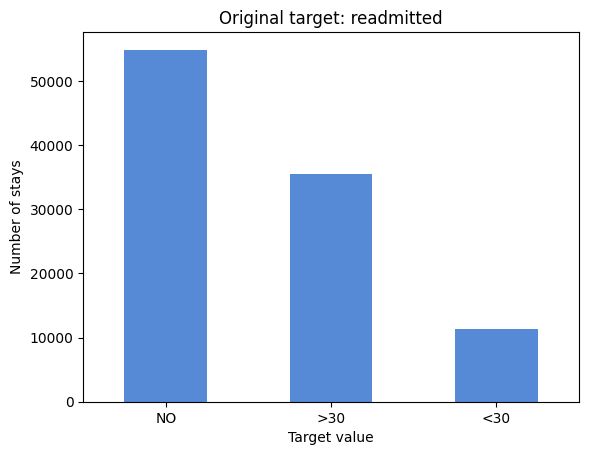

In [ ]:
# Share of each class + bar chart.
def plot_target_distribution(y, title):
    counts = y.value_counts()
    print((100 * counts / len(y)).round(2).astype(str) + " %")
    counts.plot(kind="bar", color="#578AD6")
    plt.xlabel("Target value")
    plt.ylabel("Number of stays")
    plt.title(title)
    plt.xticks(rotation=0)
    plt.show()

plot_target_distribution(df["readmitted"], "Original target: readmitted")

<30-day readmission rate: 11.16%
That is roughly 8 stays without readmission for 1 with readmission
readmitted_30d
0    88.84 %
1    11.16 %
Name: count, dtype: object


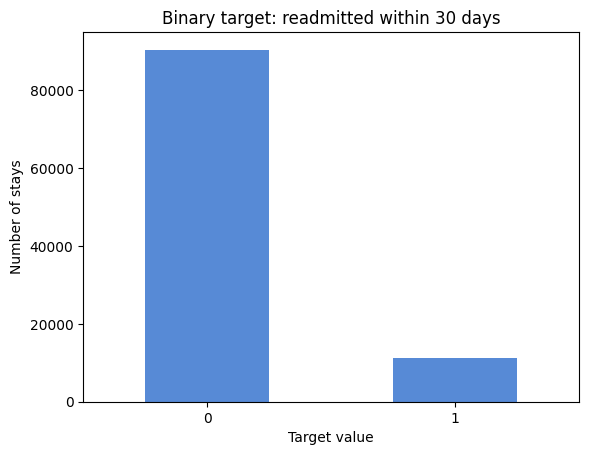

In [ ]:
# Binary target: 1 = readmitted within 30 days, 0 = "NO" or ">30".
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

print(f"<30-day readmission rate: {df['readmitted_30d'].mean():.2%}")
ratio = (1 - df["readmitted_30d"].mean()) / df["readmitted_30d"].mean()
print(f"That is roughly {ratio:.0f} stays without readmission for 1 with readmission")

plot_target_distribution(df["readmitted_30d"], "Binary target: readmitted within 30 days")

Is accuracy enough? No. Only 11% of the stays are readmitted within 30 days, so a model that always says "no" gets 89% accuracy and finds nobody. We use recall, precision, F1, ROC-AUC and PR-AUC instead.

**Problem framing**

At discharge, we predict if a diabetic patient will be readmitted within 30 days (1 = yes, 0 = no or after 30 days). The hospital can then call or see the patients at risk first.

**Prediction-time test (Session 1):** all our features are known at discharge. Only `readmitted` is known later, so it is the target, never a feature.

**Decisions from the EDA**
1. Binary target `readmitted_30d`; `readmitted` removed from the features.
2. Identifiers (`encounter_id`, `patient_nbr`) removed from the features.
3. Death / hospice stays removed.
4. Metrics: recall, precision, F1, ROC-AUC, PR-AUC (not accuracy).
5. Split and CV folds grouped by patient.
6. Drop `weight`; "Missing" category for `medical_specialty` and `payer_code`; `*_id` as categories; group the ICD-9 diagnosis codes.
7. Sensitive attribute for the fairness audit: race.

# Feature Engineering

We clean the data and split it into a train set and a test set.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Remove the death / hospice stays, the weight column and the old target.
data = df[~is_death_hospice].drop(columns=["weight", "readmitted"]).reset_index(drop=True)
print("Stays kept:", len(data))
print(f"<30-day readmission rate: {data['readmitted_30d'].mean():.2%}")

Stays kept: 99343
<30-day readmission rate: 11.39%


We split **by patient** with `StratifiedGroupKFold`: a patient is either in train or in test, and both sets keep about the same readmission rate. We get about 80% / 20% (79,625 and 19,718 stays).

In [ ]:
# 5 patient-grouped and stratified parts: the first part is the test set (~20%), the rest the train set.
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(data, data["readmitted_30d"], groups=data["patient_nbr"]))
train = data.iloc[train_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(train)} stays | readmission rate {train['readmitted_30d'].mean():.2%}")
print(f"Test : {len(test)} stays | readmission rate {test['readmitted_30d'].mean():.2%}")
print("Patients in both sets:", len(set(train["patient_nbr"]) & set(test["patient_nbr"])))
# Safety checks: no missing patient id and no patient in both sets.
assert train["patient_nbr"].notna().all()
assert test["patient_nbr"].notna().all()
assert set(train["patient_nbr"]).isdisjoint(set(test["patient_nbr"])), "Patient overlap in split."

Train: 79625 stays | readmission rate 11.46%
Test : 19718 stays | readmission rate 11.10%
Patients in both sets: 0


We now explore the train set only, so that the test set stays untouched.

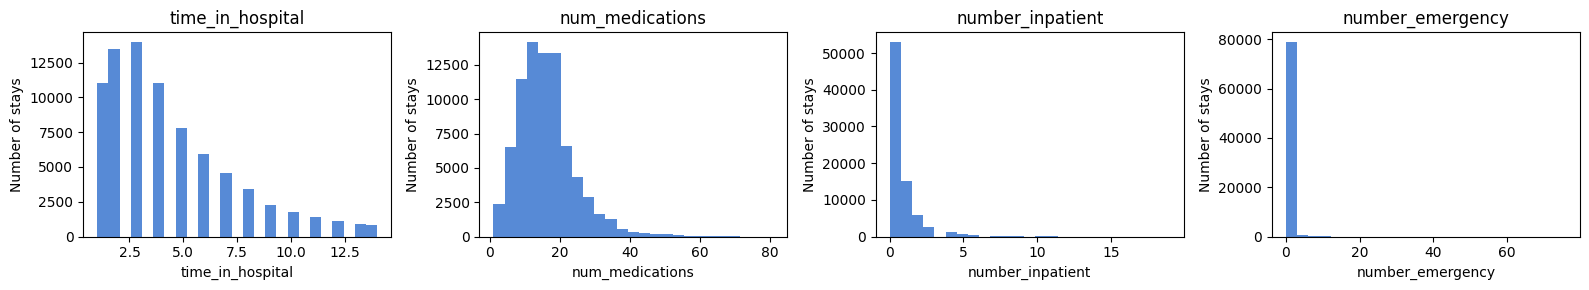

In [ ]:
# Distribution of four numerical features (train set only).
variables = ["time_in_hospital", "num_medications", "number_inpatient", "number_emergency"]
variables = [column for column in variables if column in train.columns]
fig, axes = plt.subplots(1, len(variables), figsize=(4 * len(variables), 3), squeeze=False)
for ax, column in zip(axes.ravel(), variables):
    ax.hist(train[column].dropna(), bins=25, color="#578AD6")
    ax.set(title=column, xlabel=column, ylabel="Number of stays")
plt.tight_layout()
plt.show()

In [ ]:
# Number of stays and readmission rate for each value of a feature (small groups are removed).
def readmission_rate_by_group(data, feature, min_count=100):
    table = (
        data.groupby(feature, dropna=False, observed=True)["readmitted_30d"]
        .agg(n_stays="size", readmission_rate="mean")
    )
    return table.loc[table["n_stays"] >= min_count]


# Same thing as a bar chart, with the overall rate as a red line.
def plot_rate_by_group(data, feature, min_count=100):
    table = readmission_rate_by_group(data, feature, min_count)
    if table.empty:
        print(f"{feature}: no group meets min_count={min_count}.")
        return table
    table["readmission_rate"].plot.bar(figsize=(7, 3), color="#578AD6")
    plt.axhline(data["readmitted_30d"].mean(), color="red", linestyle="--", label="Overall rate")
    plt.xlabel(feature)
    plt.ylabel("Recorded <30-day readmission rate")
    plt.title(f"Training data: {feature}")
    plt.xticks(rotation=45, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()
    return table


--- number_inpatient ---


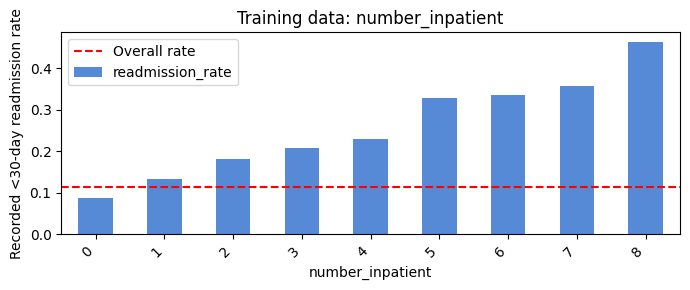

,n_stays,readmission_rate
number_inpatient,,
0,52997,0.087
1,15249,0.133
2,5932,0.182
3,2643,0.208
4,1241,0.230
5,626,0.327
6,379,0.335
7,216,0.356
8,121,0.463



--- time_in_hospital ---


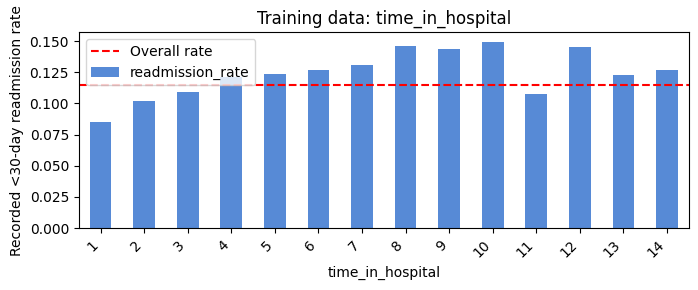

,n_stays,readmission_rate
time_in_hospital,,
1,11012,0.085
2,13509,0.102
3,13972,0.109
4,11052,0.121
5,7829,0.124
6,5926,0.127
7,4590,0.131
8,3411,0.146
9,2275,0.144



--- age ---


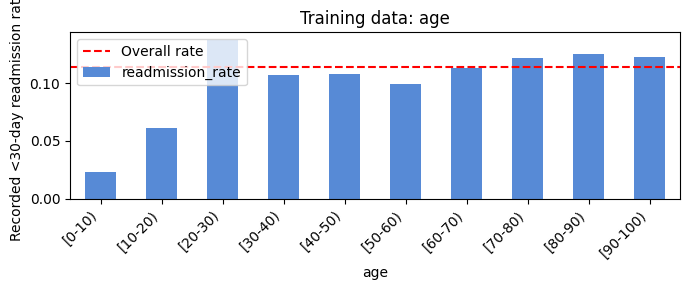

,n_stays,readmission_rate
age,,
[0-10),130,0.023
[10-20),537,0.061
[20-30),1317,0.137
[30-40),2982,0.108
[40-50),7738,0.108
[50-60),13676,0.099
[60-70),17708,0.113
[70-80),20306,0.122
[80-90),13101,0.126


In [ ]:
for feature in ["number_inpatient", "time_in_hospital", "age"]:
    print(f"\n--- {feature} ---")
    display(plot_rate_by_group(train, feature).round(3))

`number_inpatient` looks useful: the readmission rate goes from 8.7% (no past stay) to 18.2% (2 stays) and 46.3% (8 stays). But this is an association, not a cause: very sick patients have both more past stays and more readmissions.

In [ ]:
# Correlation of each numerical feature with the target.
correlation = train[num_cols + ["readmitted_30d"]].corr()["readmitted_30d"]
display(correlation.drop("readmitted_30d").sort_values(key=abs, ascending=False).round(3))

,readmitted_30d
number_inpatient,0.166
number_emergency,0.058
number_diagnoses,0.054
time_in_hospital,0.044
num_medications,0.041
num_lab_procedures,0.023
number_outpatient,0.017
num_procedures,-0.010


In [ ]:
# Readmission rate by race, gender and age (descriptive only; fairness is audited later).
for feature in ["race", "gender", "age"]:
    display(readmission_rate_by_group(train, feature, min_count=30).round(3))

,n_stays,readmission_rate
race,,
AfricanAmerican,15194,0.114
Asian,509,0.104
Caucasian,59395,0.116
Hispanic,1629,0.099
Other,1158,0.099
NaN,1740,0.089


,n_stays,readmission_rate
gender,,
Female,42755,0.115
Male,36867,0.114


,n_stays,readmission_rate
age,,
[0-10),130,0.023
[10-20),537,0.061
[20-30),1317,0.137
[30-40),2982,0.108
[40-50),7738,0.108
[50-60),13676,0.099
[60-70),17708,0.113
[70-80),20306,0.122
[80-90),13101,0.126


We create three features and group the diagnoses. They only use values of the same row, so there is no leakage. They are computed in a function, `add_features`, which is the first step of the Pipeline.

- `n_prior_visits`: outpatient + emergency + inpatient visits in the past year.
- `n_med_changes`: number of diabetes medications whose dose went up or down (unstable diabetes).
- `age_years`: middle of the age bracket (`[70-80)` → 75).
- `diag_1/2/3_group`: the 700+ ICD-9 codes grouped into 9 families, as in Strack et al. (2014) (we used AI help for this grouping). Missing diagnosis = "Missing".

In [ ]:
# The 23 diabetes medication columns (values: No, Steady, Up, Down).
med_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
            "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
            "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide", "examide",
            "citoglipton", "insulin", "glyburide.metformin", "glipizide.metformin",
            "glimepiride.pioglitazone", "metformin.rosiglitazone", "metformin.pioglitazone"]

# ICD-9 code -> diagnosis family (grouping of Strack et al., 2014).
def icd9_group(code):
    if pd.isna(code) or str(code).strip() in {"", "?"}:
        return "Missing"

    text = str(code).strip().upper()
    if text.startswith(("V", "E")):  # special codes
        return "Other"

    try:
        number = float(text)
    except ValueError as exc:
        raise ValueError(f"Unrecognised ICD-9 code: {code!r}") from exc

    if not np.isfinite(number) or number < 0:
        raise ValueError(f"Invalid ICD-9 code: {code!r}")

    family = int(number)  # 250.83 -> 250
    if family == 250:
        return "Diabetes"
    if 390 <= family <= 459 or family == 785:
        return "Circulatory"
    if 460 <= family <= 519 or family == 786:
        return "Respiratory"
    if 520 <= family <= 579 or family == 787:
        return "Digestive"
    if 580 <= family <= 629 or family == 788:
        return "Genitourinary"
    if 710 <= family <= 739:
        return "Musculoskeletal"
    if 800 <= family <= 999:
        return "Injury"
    if 140 <= family <= 239:
        return "Neoplasms"
    return "Other"

# New features. Each one only uses values of the same row (no leakage).
def add_features(data):
    data = data.copy()
    data["n_prior_visits"] = data["number_outpatient"] + data["number_emergency"] + data["number_inpatient"]
    data["n_med_changes"] = data[med_cols].isin(["Up", "Down"]).sum(axis=1)
    data["age_years"] = data["age"].str.extract(r"\[(\d+)-").astype(int)[0] + 5  # [70-80) -> 75
    for col in ["diag_1", "diag_2", "diag_3"]:
        data[col + "_group"] = data[col].map(icd9_group)
    # The *_id codes become text, so they are treated as categories.
    for col in coded_cols:
        data[col] = data[col].astype(str)
    return data

train_fe = add_features(train)
train_fe[["n_prior_visits", "n_med_changes", "age", "age_years", "diag_1", "diag_1_group"]].head()

,n_prior_visits,n_med_changes,age,age_years,diag_1,diag_1_group
0,0,0,[0-10),5,250.83,Diabetes
1,0,1,[10-20),15,276,Other
2,0,1,[30-40),35,8,Other
3,0,0,[50-60),55,414,Circulatory
4,0,0,[60-70),65,414,Circulatory


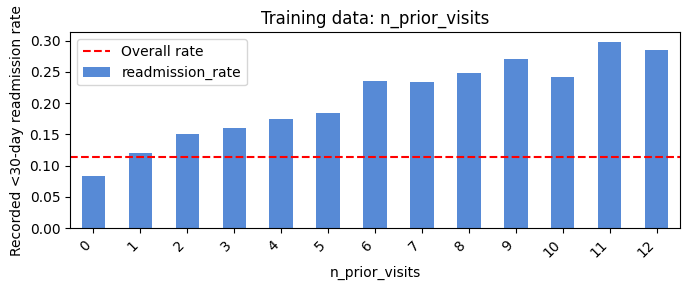

                n_stays  readmission_rate
n_prior_visits                           
0                 43746             0.084
1                 15629             0.120
2                  7879             0.151
3                  4604             0.161
4                  2732             0.174
5                  1612             0.184
6                  1007             0.235
7                   684             0.234
8                   439             0.248
9                   348             0.270
10                  219             0.242
11                  191             0.298
12                  105             0.286 



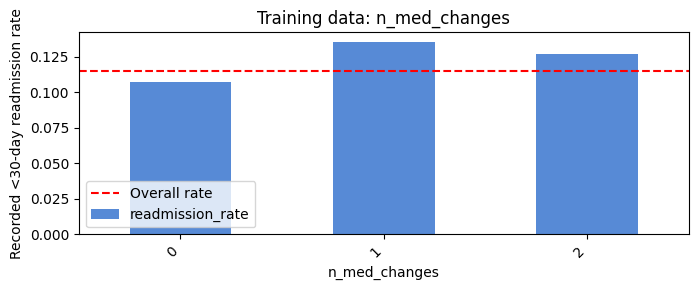

               n_stays  readmission_rate
n_med_changes                           
0                57997             0.107
1                20504             0.135
2                 1033             0.127 



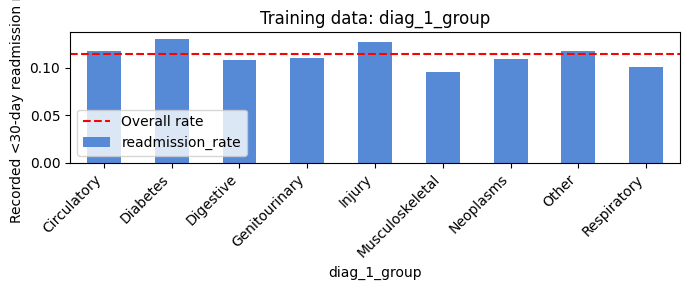

                 n_stays  readmission_rate
diag_1_group                              
Circulatory        23766             0.118
Diabetes            6922             0.131
Digestive           7529             0.109
Genitourinary       4055             0.111
Injury              5509             0.127
Musculoskeletal     3923             0.095
Neoplasms           2494             0.109
Other              14232             0.118
Respiratory        11181             0.100 



In [ ]:
for feature in ["n_prior_visits", "n_med_changes", "diag_1_group"]:
    print(plot_rate_by_group(train_fe, feature).round(3), "\n")

The readmission rate grows from 8.4% (no prior visit) to about 30% (11 visits). One medication change: 13.5% vs 10.7% without. Diagnosis family: from 9.5% (musculoskeletal) to 13.1% (diabetes). Again, these are associations.

Columns used by the model: the original columns + the new features (`age_years` replaces `age`, the diagnosis groups replace the raw codes). `race` is **not** used; it is kept for the fairness audit. Removing it does not make the model fair by itself (Session 9).

The preprocessing is in a Pipeline, fitted inside each CV fold, so the validation fold never leaks into it (Session 5).

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

numerical_features = num_cols + ["n_prior_visits", "n_med_changes", "age_years"]
categorical_features = [
    "gender", "payer_code", "medical_specialty", "A1Cresult", "max_glu_serum",
    "change", "diabetesMed", "diag_1_group", "diag_2_group", "diag_3_group"
] + coded_cols + med_cols

# Numerical columns: median imputation, then scaling.
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
# Categorical columns: "Missing" as a category, then one-hot encoding.
# Categories seen fewer than 50 times are grouped; unknown categories do not crash the model.
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                             sparse_output=False))
])
column_transformer = ColumnTransformer([
    ("num", numeric_steps, numerical_features),
    ("cat", categorical_steps, categorical_features)
])
# Full preprocessing: new features first, then the column transformations.
preprocessor = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("columns", column_transformer)
])

# Features = everything except the ids, the target and race (kept for the fairness audit).
not_features = ["encounter_id", "patient_nbr", "race", "readmitted_30d"]
X_train, y_train = train.drop(columns=not_features), train["readmitted_30d"]
X_test, y_test = test.drop(columns=not_features), test["readmitted_30d"]
groups_train = train["patient_nbr"]
race_train, race_test = train["race"], test["race"]

print(f"{len(numerical_features)} numerical and {len(categorical_features)} categorical features")
print("Preprocessor defined; it will be fitted inside cross-validation.")

11 numerical and 36 categorical features
Preprocessor defined; it will be fitted inside cross-validation.


# Class Imbalance Handling

**How we compare models:** 5-fold CV on the train set, grouped by patient and stratified. All models use the same folds.

**Metrics** (class 1 = readmitted within 30 days):
- **Recall**: share of readmitted patients that we flag. Missing them is the costly error.
- **Precision**: share of flagged patients really readmitted.
- **F1**: balance of precision and recall.
- **ROC-AUC**: quality of the ranking (0.5 = random).
- **PR-AUC**: ranking quality focused on the rare class (random ≈ 0.11 here). **This is our main metric.**

Note: "PR-AUC" in this notebook is the **Average Precision** from `average_precision_score` (Sessions 6 and 8).

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# 5 folds grouped by patient and stratified, saved once so that every model uses the same folds.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, groups=groups_train))

# All the metrics; a stay is flagged if its score >= threshold.
def evaluate(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

# Out-of-fold scores: the whole Pipeline is refitted in each fold.
def cv_proba(model):
    pipe = Pipeline([("preprocessing", clone(preprocessor)), ("model", model)])
    return cross_val_predict(pipe, X_train, y_train, cv=folds,
                             method="predict_proba")[:, 1]

proba = {
    "Dummy (always 0)": cv_proba(DummyClassifier(strategy="prior")),
    "Logistic Regression": cv_proba(LogisticRegression(max_iter=2000)),
    "Logistic Regression + class weights": cv_proba(LogisticRegression(max_iter=2000, class_weight="balanced")),
}
pd.DataFrame({name: evaluate(y_train, p) for name, p in proba.items()}).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (always 0),0.885,0.000,0.000,0.000,0.492,0.113
Logistic Regression,0.885,0.481,0.017,0.033,0.663,0.216
Logistic Regression + class weights,0.668,0.184,0.552,0.276,0.664,0.215


- The dummy model gets 88.5% accuracy but recall 0: accuracy is useless here. (Its ROC-AUC is 0.492, not 0.5, because its constant score changes a little between folds.)
- Logistic Regression without weights ranks well (PR-AUC 0.216, twice the random level), but at threshold 0.5 it flags almost nobody (recall 1.7%).
- With `class_weight="balanced"`, readmitted stays count about 7.7 times more. Recall goes up to 55.2% (precision 18.4%), but PR-AUC and ROC-AUC do not change: the weights shift the scores, they do not improve the ranking.

0.5 is an arbitrary threshold. We look at precision, recall and F1 for all thresholds.

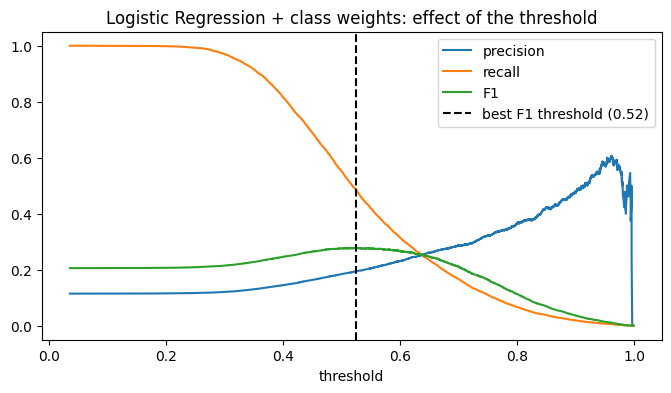

No class weights, best threshold 0.122: {'accuracy': 0.7, 'precision': 0.192, 'recall': 0.504, 'f1': 0.278, 'roc_auc': np.float64(0.663), 'pr_auc': np.float64(0.216)}
Class weights,    best threshold 0.524: {'accuracy': 0.71, 'precision': 0.195, 'recall': 0.487, 'f1': 0.278, 'roc_auc': np.float64(0.664), 'pr_auc': np.float64(0.215)}


In [ ]:
from sklearn.metrics import precision_recall_curve


# Threshold with the best F1.
def best_f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]  # the last point has no threshold

p = proba["Logistic Regression + class weights"]
precision, recall, thresholds = precision_recall_curve(y_train, p)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best = best_f1_threshold(y_train, p)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.plot(thresholds, f1[:-1], label="F1")
plt.axvline(best, color="black", linestyle="--", label=f"best F1 threshold ({best:.2f})")
plt.xlabel("threshold")
plt.title("Logistic Regression + class weights: effect of the threshold")
plt.legend()
plt.show()

# Metrics at the best threshold, without and with class weights.
print(f"No class weights, best threshold {best_f1_threshold(y_train, proba['Logistic Regression']):.3f}:",
      {k: round(v, 3) for k, v in evaluate(y_train, proba['Logistic Regression'],
                                           best_f1_threshold(y_train, proba['Logistic Regression'])).items()})
print(f"Class weights,    best threshold {best:.3f}:",
      {k: round(v, 3) for k, v in evaluate(y_train, p, best).items()})

Without weights, the best threshold is 0.122; with weights, 0.524. Both give F1 = 0.278. So class weights and threshold tuning do a similar job here (Session 6).

We also compare four remedies with Logistic Regression, on the same folds:
- nothing;
- class weights;
- random undersampling (remove majority stays);
- SMOTE (create synthetic readmitted stays).

Resampling is done inside the imblearn Pipeline, so only the training folds are resampled, never the validation fold (Session 6).

In [ ]:
# imblearn's Pipeline allows a resampling step (applied to the training folds only).
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

remedy_proba = {
    "Nothing": proba["Logistic Regression"],
    "Class weights": proba["Logistic Regression + class weights"],
}
for name, sampler in {"Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
                      "SMOTE": SMOTE(random_state=RANDOM_STATE)}.items():
    # imblearn does not accept a Pipeline inside its Pipeline, so we list the preprocessing steps.
    pipe = ImbPipeline(list(preprocessor.steps) + [("sampler", sampler),
                                                   ("model", LogisticRegression(max_iter=2000))])
    remedy_proba[name] = cross_val_predict(pipe, X_train, y_train, cv=folds,
                                           method="predict_proba")[:, 1]

rows = {}
for name, p in remedy_proba.items():
    best_t = best_f1_threshold(y_train, p)
    fold_pr_auc = [average_precision_score(y_train.iloc[test_fold], p[test_fold]) for _, test_fold in folds]
    at_half, at_best = evaluate(y_train, p), evaluate(y_train, p, best_t)
    rows[name] = {"PR-AUC": np.mean(fold_pr_auc), "PR-AUC fold std": np.std(fold_pr_auc),
                  "ROC-AUC": at_half["roc_auc"],
                  "recall @0.5": at_half["recall"], "precision @0.5": at_half["precision"],
                  "best-F1 threshold": best_t, "F1 @best threshold": at_best["f1"]}
remedies_table = pd.DataFrame(rows).T
display(remedies_table.round(3))

# A remedy is "better" only if it beats class weights by more than the fold-to-fold std.
reference = remedies_table.loc["Class weights"]
for name in ["Nothing", "Random undersampling", "SMOTE"]:
    gain = remedies_table.loc[name, "PR-AUC"] - reference["PR-AUC"]
    if gain > reference["PR-AUC fold std"]:
        verdict = "better"
    elif gain < -reference["PR-AUC fold std"]:
        verdict = "worse"
    else:
        verdict = "no real difference"
    print(f"{name:22s} PR-AUC difference vs class weights: {gain:+.4f} (fold std {reference['PR-AUC fold std']:.4f}) -> {verdict}")

,PR-AUC,PR-AUC fold std,ROC-AUC,recall @0.5,precision @0.5,best-F1 threshold,F1 @best threshold
Nothing,0.216,0.009,0.663,0.017,0.481,0.122,0.278
Class weights,0.216,0.010,0.664,0.552,0.184,0.524,0.278
Random undersampling,0.213,0.009,0.661,0.560,0.180,0.532,0.277
SMOTE,0.208,0.009,0.648,0.555,0.173,0.560,0.269


Nothing                PR-AUC difference vs class weights: +0.0005 (fold std 0.0096) -> no real difference
Random undersampling   PR-AUC difference vs class weights: -0.0030 (fold std 0.0096) -> no real difference
SMOTE                  PR-AUC difference vs class weights: -0.0081 (fold std 0.0096) -> no real difference


PR-AUC compares the ranking. "F1 @best threshold" compares the methods once each has its own threshold.

**Result: no real difference.** PR-AUC: 0.216 (nothing), 0.216 (class weights), 0.213 (undersampling), 0.208 (SMOTE). All differences are smaller than the fold std (≈ 0.010).

**Our choice: class weights in all models + a threshold chosen on the out-of-fold predictions.** It is the simplest (no extra step, all three models accept it). Undersampling throws away 87% of the majority stays, and SMOTE creates fake values between one-hot columns.

Session 6 says the weight is a hyperparameter to validate. We tested w = 1 and "balanced" (≈ 7.7): same PR-AUC, so we did not tune it more. The cost of the weights is bad calibration (checked later).

# Modelling Progression & Pipeline

Each model is the last step of a Pipeline with all the preprocessing (raw columns in, score out). We compare three models with a hand-picked starting configuration (called "default" in the code):
1. **Logistic Regression**: simple linear baseline (Session 1).
2. **Random Forest**: average of many decorrelated trees (Session 4).
3. **LightGBM**: gradient boosting, trees added one after another to correct the errors (Session 4).

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import time


# Preprocessing + model in one Pipeline (clone = fresh copy).
def make_pipeline(model):
    return Pipeline([("preprocessing", clone(preprocessor)), ("model", clone(model))])

# Starting configurations (called "default" in the code), all with class weights.
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_leaf=5,
                                            max_features="sqrt", class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight="balanced",
                               random_state=RANDOM_STATE, verbose=-1),
}
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

# 5-fold CV; the train scores are kept to detect over-fitting.
results = {}
for name, model in models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=folds,
                            scoring=scoring, return_train_score=True)
    results[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}
    results[name]["pr_auc_std"] = scores["test_pr_auc"].std()
    results[name]["train_pr_auc"] = scores["train_pr_auc"].mean()
    results[name]["fit_time_s"] = scores["fit_time"].mean()

comparison = pd.DataFrame(results).T
display(comparison.round(3))

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,pr_auc_std,train_pr_auc,fit_time_s
Logistic Regression,0.668,0.618,0.184,0.552,0.276,0.664,0.216,0.010,0.221,14.735
Random Forest,0.856,0.559,0.286,0.173,0.215,0.670,0.220,0.013,0.884,42.949
LightGBM,0.685,0.619,0.189,0.533,0.280,0.668,0.230,0.015,0.378,6.927


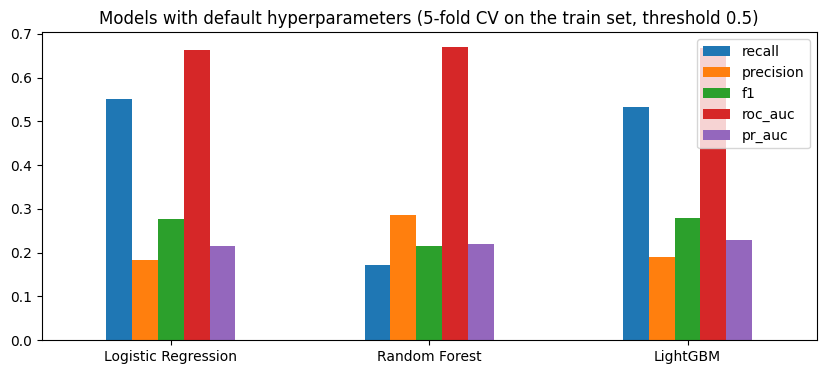

In [ ]:
comparison[["recall", "precision", "f1", "roc_auc", "pr_auc"]].plot(kind="bar", figsize=(10, 4))
plt.title("Models with default hyperparameters (5-fold CV on the train set, threshold 0.5)")
plt.xticks(rotation=0)
plt.show()

- **Logistic Regression**: PR-AUC 0.216, almost no over-fitting (train 0.221).
- **Random Forest**: PR-AUC 0.220, but strong over-fitting (train 0.884) and the slowest (27 s per fit). At 0.5 its recall is only 17.3%, so each model needs its own threshold.
- **LightGBM**: best PR-AUC (0.230), moderate over-fitting (train 0.378), fastest (4 s per fit).

The gains over Logistic Regression (+0.004 and +0.014) are about the size of the fold std (0.010–0.015). Readmission is hard to predict from this data.

**Do the new features help?** Ablation: we start from the raw columns and add the new features one at a time, with the same folds. We compare the PR-AUC fold by fold.

In [ ]:
from sklearn.model_selection import cross_val_score

# Columns shared by all the variants.
base_categorical = (["gender", "payer_code", "medical_specialty", "A1Cresult", "max_glu_serum", "change", "diabetesMed"]
                    + coded_cols + med_cols)
raw_diagnoses = ["diag_1", "diag_2", "diag_3"]
diagnosis_groups = ["diag_1_group", "diag_2_group", "diag_3_group"]


# Same preprocessing as before, but with a chosen list of extra columns.
def preprocessor_variant(extra_numerical, extra_categorical):
    columns = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_cols + extra_numerical),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                                    sparse_output=False))]), base_categorical + extra_categorical),
    ])
    return Pipeline([("features", FunctionTransformer(add_features)), ("columns", columns)])


# Variant = (extra numerical columns, extra categorical columns).
variants = {
    "raw columns only":                         ([], ["age"] + raw_diagnoses),
    "+ n_prior_visits":                         (["n_prior_visits"], ["age"] + raw_diagnoses),
    "+ n_med_changes":                          (["n_med_changes"], ["age"] + raw_diagnoses),
    "+ age_years (replaces the age bracket)":   (["age_years"], raw_diagnoses),
    "+ diagnosis groups (replace ICD-9 codes)": ([], ["age"] + diagnosis_groups),
    "all of them (our pipeline)":               (["n_prior_visits", "n_med_changes", "age_years"], diagnosis_groups),
}

# PR-AUC of each fold, for each model and variant.
fold_scores = {}
for model_name in ["Logistic Regression", "LightGBM"]:
    for variant, (extra_num, extra_cat) in variants.items():
        pipe = Pipeline([("preprocessing", preprocessor_variant(extra_num, extra_cat)),
                         ("model", clone(models[model_name]))])
        fold_scores[(model_name, variant)] = cross_val_score(pipe, X_train, y_train, cv=folds,
                                                              scoring="average_precision")

# Gain compared with the raw columns, fold by fold.
rows = []
for (model_name, variant), scores in fold_scores.items():
    gain = scores - fold_scores[(model_name, "raw columns only")]
    rows.append({"model": model_name, "variant": variant, "PR-AUC": scores.mean(), "fold std": scores.std(),
                 "gain vs raw": gain.mean(), "std of the gain": gain.std(), "folds where it helps": f"{(gain > 0).sum()}/5"})
ablation_table = pd.DataFrame(rows).set_index(["model", "variant"])
display(ablation_table.round(4))

PR-AUC  fold std  gain vs raw  std of the gain folds where it helps
model               variant                                                                                                      
Logistic Regression raw columns only                          0.2142    0.0085       0.0000           0.0000                  0/5
                    + n_prior_visits                          0.2142    0.0086      -0.0000           0.0001                  2/5
                    + n_med_changes                           0.2142    0.0086       0.0000           0.0001                  3/5
                    + age_years (replaces the age bracket)    0.2139    0.0086      -0.0003           0.0005                  1/5
                    + diagnosis groups (replace ICD-9 codes)  0.2160    0.0095       0.0018           0.0019                  4/5
                    all of them (our pipeline)                0.2155    0.0095       0.0013           0.0021                  3/5
LightGBM            raw columns only                          0.2269    0.0116       0.0000           0.0000                  0/5
                    + n_prior_visits                          0.2280    0.0122       0.0011           0.0014                  4/5
                    + n_med_changes                           0.2278    0.0130       0.0009           0.0022                  4/5
                    + age_years (replaces the age bracket)    0.2271    0.0129       0.0002           0.0019                  2/5
                    + diagnosis groups (replace ICD-9 codes)  0.2290    0.0128       0.0021           0.0027                  4/5
                    all of them (our pipeline)                0.2301    0.0147       0.0032           0.0038                  4/5

All gains are within noise (at most +0.002 for Logistic Regression and +0.003 for LightGBM, with a std of 0.002–0.004). We keep the features because they are cheap, leakage-free and easy to explain.

# Hyperparameter Tuning

We tune the three models with **Optuna** (TPE sampler, Session 5) and log everything with **MLflow**.

- Each trial = 5-fold CV of the whole Pipeline, on the same folds. Optuna maximises the mean PR-AUC. The test set is not used.
- The first trial is the starting configuration.
- MLflow logs the starting configurations, every trial (parameters, mean and std PR-AUC), and one parent run per model (best parameters, plot, table of trials, best Pipeline).

Searched hyperparameters: `C` for Logistic Regression (Session 2); trees, depth, leaf size and features per split for Random Forest; trees, learning rate, leaves, leaf size, sampling and L2 for LightGBM (Session 4).

The best score is a bit optimistic because it was chosen on these folds. Like in Session 5, we keep an untouched test set instead of using nested CV.

In [ ]:
import optuna
import mlflow
import mlflow.sklearn

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("diabetes-readmission")

# Log the three starting configurations.
for name, row in comparison.iterrows():
    with mlflow.start_run(run_name=f"{name} - default"):
        mlflow.log_param("model", name)
        mlflow.log_params(models[name].get_params())
        mlflow.log_metrics({"cv_" + metric: value for metric, value in row.items()})


# Model with the hyperparameters proposed by Optuna (log=True: search on a log scale).
def build_model(name, trial):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, class_weight="balanced",
                                  C=trial.suggest_float("C", 1e-4, 10, log=True))
    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 4, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 200, log=True),
            max_features=trial.suggest_categorical("max_features", ["sqrt", 0.25]),
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 1000, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
            num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 10, 500, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
            class_weight="balanced", random_state=RANDOM_STATE, verbose=-1)


# Score of a trial = mean CV PR-AUC. Each trial is logged in MLflow.
def objective(trial, name):
    model = build_model(name, trial)
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=folds,
                             scoring="average_precision")
    with mlflow.start_run(run_name=f"{name} - trial {trial.number}", nested=True):
        mlflow.log_param("model", name)
        mlflow.log_params(trial.params)
        mlflow.log_metric("cv_pr_auc", scores.mean())
        mlflow.log_metric("cv_pr_auc_std", scores.std())
    return scores.mean()

2026/10/19 09:19:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 09:19:29 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 09:19:33 INFO mlflow.tracking.fluent: Experiment with name 'diabetes-readmission' does not exist. Creating a new experiment.


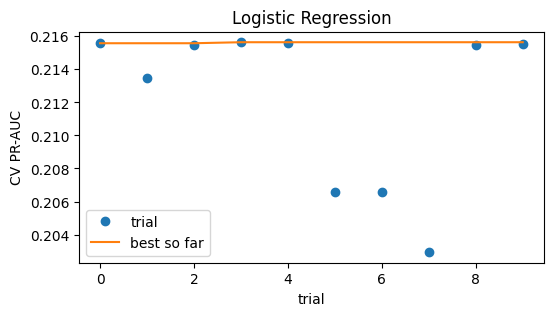

2026/10/19 09:29:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression: best CV PR-AUC = 0.2156 (9.7 min)
   best hyperparameters: {'C': 0.4570563099801455}


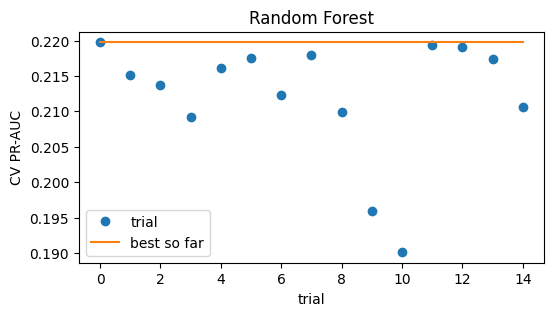

2026/10/19 10:12:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest: best CV PR-AUC = 0.2198 (43.5 min)
   best hyperparameters: {'n_estimators': 300, 'max_depth': 30, 'min_samples_leaf': 5, 'max_features': 'sqrt'}


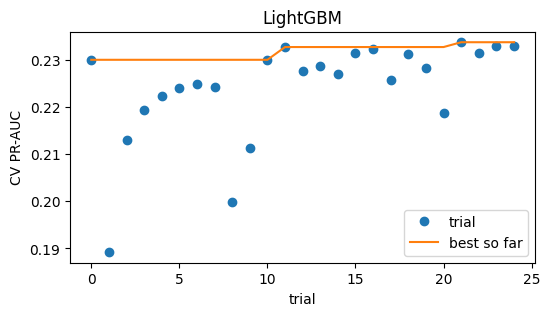

2026/10/19 10:34:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LightGBM: best CV PR-AUC = 0.2338 (21.5 min)
   best hyperparameters: {'n_estimators': 500, 'learning_rate': 0.017215826252959303, 'num_leaves': 56, 'min_child_samples': 58, 'subsample': 0.9078778017881187, 'colsample_bytree': 0.797875473786174, 'reg_lambda': 0.010916002791946197}


In [ ]:
n_trials = {"Logistic Regression": 10, "Random Forest": 15, "LightGBM": 25}

# Starting configurations = first trial of each study.
default_params = {
    "Logistic Regression": {"C": 1.0},
    "Random Forest": {"n_estimators": 300, "max_depth": 30, "min_samples_leaf": 5, "max_features": "sqrt"},
    "LightGBM": {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 20,
                 "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 0.001},
}
studies = {}

for name, n in n_trials.items():
    start = time.time()
    with mlflow.start_run(run_name=f"{name} - tuning"):  # parent run
        study = optuna.create_study(direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
        study.enqueue_trial(default_params[name])
        study.optimize(lambda trial: objective(trial, name), n_trials=n)
        studies[name] = study

        mlflow.log_param("model", name)
        mlflow.log_param("n_trials", n)
        mlflow.log_params({"best_" + k: v for k, v in study.best_params.items()})
        mlflow.log_metric("best_cv_pr_auc", study.best_value)

        # Score of each trial and best score so far.
        fig, ax = plt.subplots(figsize=(6, 3))
        values = [t.value for t in study.trials]
        ax.plot(values, "o", label="trial")
        ax.plot(np.maximum.accumulate(values), label="best so far")
        ax.set(title=name, xlabel="trial", ylabel="CV PR-AUC")
        ax.legend()
        mlflow.log_figure(fig, "optimisation_history.png")
        plt.show()

        # Artifacts: table of all trials + best Pipeline refitted on the whole train set.
        mlflow.log_text(study.trials_dataframe().to_csv(index=False), "trials.csv")
        best_pipeline = make_pipeline(build_model(name, optuna.trial.FixedTrial(study.best_params)))
        mlflow.sklearn.log_model(best_pipeline.fit(X_train, y_train), name="model",
                                 serialization_format="cloudpickle")

    print(f"{name}: best CV PR-AUC = {study.best_value:.4f} ({(time.time() - start) / 60:.1f} min)")
    print("   best hyperparameters:", study.best_params)

In [ ]:
runs = mlflow.search_runs(experiment_names=["diabetes-readmission"])
trials = runs[runs["tags.mlflow.runName"].str.contains("trial")]
print(len(runs), "runs logged, of which", len(trials), "Optuna trials")

# Starting score vs best tuned score.
tuning = pd.DataFrame({
    "default": comparison["pr_auc"],
    "best after tuning": [studies[name].best_value for name in n_trials],
})
tuning["gain"] = tuning["best after tuning"] - tuning["default"]
tuning.round(4)

56 runs logged, of which 50 Optuna trials


,default,best after tuning,gain
Logistic Regression,0.2156,0.2156,0.0001
Random Forest,0.2198,0.2198,0.0000
LightGBM,0.2301,0.2338,0.0037


56 runs: 3 starting configurations + 50 trials + 3 parent runs.

- **Logistic Regression**: 0.2156 → 0.2156. Best `C` = 0.46, close to 1.
- **Random Forest**: 0.2198 → 0.2198. The starting configuration stays the best.
- **LightGBM**: 0.2301 → 0.2338, with more trees (500) and a smaller learning rate (0.017), 56 leaves and at least 58 stays per leaf. The gain is smaller than the fold std (≈ 0.015).

LightGBM stays the best model.

# Final Model Selection & Test Evaluation

Steps (Sessions 5 and 6):
1. Compare the three tuned models with the same metrics (out-of-fold, each at its best-F1 threshold). The final model is the best CV PR-AUC.
2. Its threshold = best F1 on its out-of-fold predictions.
3. Check over-fitting on the train set.
4. Refit on the whole train set and evaluate **once** on the test set.

In [ ]:
# The three tuned models.
tuned_models = {name: build_model(name, optuna.trial.FixedTrial(studies[name].best_params)) for name in studies}
oof_by_model = {name: cv_proba(model) for name, model in tuned_models.items()}

# Same metrics for the three models, each at its own best-F1 threshold.
rows = {}
for name, p in oof_by_model.items():
    t = best_f1_threshold(y_train, p)
    rows[name] = {**evaluate(y_train, p, t), "best-F1 threshold": t,
                  "CV PR-AUC (mean of folds)": studies[name].best_value}
display(pd.DataFrame(rows).T.round(3))

# Final model = best CV PR-AUC; threshold chosen on its out-of-fold scores.
final_name = max(studies, key=lambda name: studies[name].best_value)
best_model = tuned_models[final_name]
oof = oof_by_model[final_name]
threshold = best_f1_threshold(y_train, oof)
print("Final model:", final_name)
print(f"Threshold chosen on the train set: {threshold:.3f}")

,accuracy,precision,recall,f1,roc_auc,pr_auc,best-F1 threshold,CV PR-AUC (mean of folds)
Logistic Regression,0.709,0.195,0.489,0.278,0.664,0.215,0.524,0.216
Random Forest,0.695,0.194,0.526,0.283,0.670,0.219,0.371,0.220
LightGBM,0.751,0.216,0.446,0.291,0.676,0.233,0.542,0.234


Final model: LightGBM
Threshold chosen on the train set: 0.542


| tuned model | PR-AUC | F1 | recall | precision | threshold |
|---|---|---|---|---|---|
| Logistic Regression | 0.215 | 0.278 | 48.9% | 19.5% | 0.524 |
| Random Forest | 0.219 | 0.283 | 52.6% | 19.4% | 0.371 |
| LightGBM | 0.233 | 0.291 | 44.6% | 21.6% | 0.542 |

LightGBM has the best PR-AUC and F1, but the differences are small. It is our final model.

Now, the over-fitting check (train set only): train vs validation PR-AUC, and a learning curve.

Train PR-AUC     : 0.374
Validation PR-AUC: 0.234 (std 0.014)


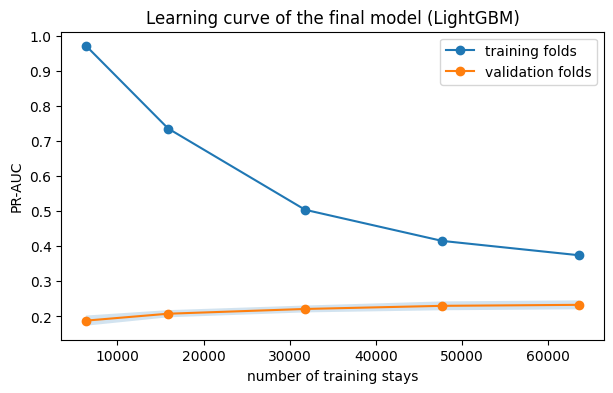

,n_train,train PR-AUC,validation PR-AUC
0,6356,0.973,0.188
1,15891,0.736,0.208
2,31783,0.504,0.221
3,47675,0.416,0.230
4,63567,0.375,0.233


In [ ]:
from sklearn.model_selection import learning_curve

# Train vs validation PR-AUC.
scores = cross_validate(make_pipeline(best_model), X_train, y_train, cv=folds,
                        scoring="average_precision", return_train_score=True)
print(f"Train PR-AUC     : {scores['train_score'].mean():.3f}")
print(f"Validation PR-AUC: {scores['test_score'].mean():.3f} (std {scores['test_score'].std():.3f})")

# Learning curve (shuffle=True because the rows are not in random order).
sizes, train_scores, val_scores = learning_curve(
    make_pipeline(best_model), X_train, y_train, cv=folds,
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], scoring="average_precision",
    shuffle=True, random_state=RANDOM_STATE)

plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="training folds")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="validation folds")
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel("number of training stays")
plt.ylabel("PR-AUC")
plt.title(f"Learning curve of the final model ({final_name})")
plt.legend()
plt.show()
pd.DataFrame({"n_train": sizes, "train PR-AUC": train_scores.mean(axis=1),
              "validation PR-AUC": val_scores.mean(axis=1)}).round(3)

Train PR-AUC 0.374 vs validation 0.234: moderate over-fitting, much less than the Random Forest (0.884 vs 0.220). Tuning did not reduce the gap (starting LightGBM: 0.378 vs 0.230).

Learning curve (Session 3): with 6,356 stays, train 0.973 and validation 0.188. With more data, the two curves get closer (validation 0.233 at the end). The validation curve still rises a little, so more data would help a bit.

In [ ]:
# Fit on the whole train set, then predict the test set (once).
final_pipeline = make_pipeline(best_model).fit(X_train, y_train)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]

final_results = pd.DataFrame({
    "train (cross-validation)": evaluate(y_train, oof, threshold),
    "test": evaluate(y_test, test_proba, threshold),
}).T
final_results.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
train (cross-validation),0.751,0.216,0.446,0.291,0.676,0.233
test,0.752,0.211,0.450,0.287,0.682,0.235


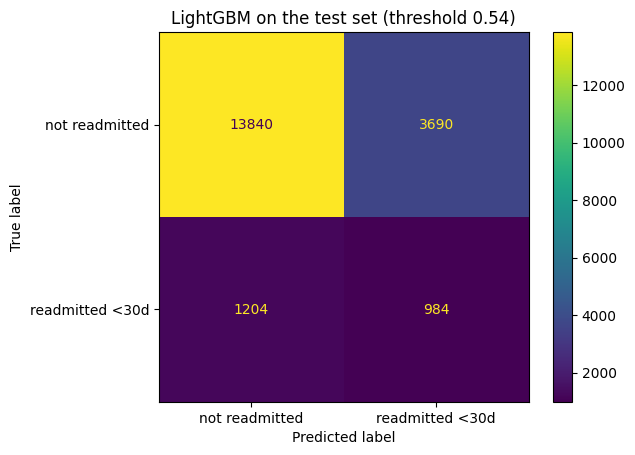

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(y_test, (test_proba >= threshold).astype(int),
                                               display_labels=["not readmitted", "readmitted <30d"])
plt.title(f"{final_name} on the test set (threshold {threshold:.2f})")

# Log the test results in MLflow.
with mlflow.start_run(run_name=f"{final_name} - final test evaluation"):
    mlflow.log_param("model", final_name)
    mlflow.log_params(studies[final_name].best_params)
    mlflow.log_param("threshold", round(threshold, 4))
    mlflow.log_metrics({"test_" + k: v for k, v in evaluate(y_test, test_proba, threshold).items()})
    mlflow.log_figure(disp.figure_, "confusion_matrix_test.png")
plt.show()

**How precise are the test scores?**
1. **Bootstrap by patient**: we resample the test patients 500 times (threshold fixed) and keep the middle 95%.
2. **Selection effect**: we re-run the CV of the final model on new folds (other seed).

In [ ]:
# Bootstrap by patient: each sample draws patients with replacement and keeps all their stays.
def bootstrap_indices(patient_ids, n_boot, seed):
    codes = pd.factorize(patient_ids)[0]
    order = np.argsort(codes, kind="stable")
    rows_by_patient = np.split(order, np.cumsum(np.bincount(codes))[:-1])
    rng = np.random.default_rng(seed)
    for _ in range(n_boot):
        sampled = rng.integers(0, len(rows_by_patient), len(rows_by_patient))
        yield np.concatenate([rows_by_patient[k] for k in sampled])


patients_test = test["patient_nbr"].values
y_arr = np.asarray(y_test)
flagged_test = test_proba >= threshold

# 500 resamples, threshold kept fixed.
boot = []
for idx in bootstrap_indices(patients_test, 500, RANDOM_STATE):
    yb, pb, fb = y_arr[idx], test_proba[idx], flagged_test[idx]
    true_pos = (fb & (yb == 1)).sum()
    boot.append({"pr_auc": average_precision_score(yb, pb), "roc_auc": roc_auc_score(yb, pb),
                 "recall": true_pos / (yb == 1).sum(), "precision": true_pos / max(fb.sum(), 1)})
boot = pd.DataFrame(boot)
boot["f1"] = 2 * boot["precision"] * boot["recall"] / (boot["precision"] + boot["recall"])

# 95% confidence interval = 2.5% and 97.5% percentiles.
test_scores = evaluate(y_test, test_proba, threshold)
interval = pd.DataFrame({"test value": {k: test_scores[k] for k in boot.columns},
                         "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975)})
display(interval.round(3))

cv_pr_auc = studies[final_name].best_value
low, high = interval.loc["pr_auc", ["95% CI low", "95% CI high"]]
print(f"CV PR-AUC of the best trial: {cv_pr_auc:.3f} | test PR-AUC: {test_scores['pr_auc']:.3f} (95% CI {low:.3f} to {high:.3f})")
print("-> the CV estimate is", "INSIDE" if low <= cv_pr_auc <= high else "OUTSIDE", "the interval of the test score")

# Same configuration on new folds (other seed), to measure the selection effect.
fresh_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2024)
fresh = cross_val_score(make_pipeline(best_model), X_train, y_train, groups=groups_train,
                        cv=fresh_cv, scoring="average_precision")
print(f"PR-AUC on fresh folds: {fresh.mean():.3f} (std {fresh.std():.3f}) | on the folds used for tuning: {cv_pr_auc:.3f}")
print(f"-> selection effect on the folds: {cv_pr_auc - fresh.mean():+.3f}")

,test value,95% CI low,95% CI high
pr_auc,0.235,0.213,0.258
roc_auc,0.682,0.668,0.695
recall,0.450,0.425,0.476
precision,0.211,0.196,0.225
f1,0.287,0.269,0.305


CV PR-AUC of the best trial: 0.234 | test PR-AUC: 0.235 (95% CI 0.213 to 0.258)
-> the CV estimate is INSIDE the interval of the test score
PR-AUC on fresh folds: 0.233 (std 0.012) | on the folds used for tuning: 0.234
-> selection effect on the folds: +0.001


The CV score (0.234) is inside the test interval (0.213–0.258): the gap between CV and test is just noise. On new folds, PR-AUC = 0.233: the selection effect is only +0.001.

**Conclusion**
- Final model: tuned LightGBM, threshold 0.542.
- Test: PR-AUC 0.235, ROC-AUC 0.682, recall 45.0%, precision 21.1%, F1 0.287.
- Test and CV agree (PR-AUC 0.235 vs 0.234, recall 45.0% vs 44.6%), so the over-fitting is not harmful.
- In practice: the model finds 45% of the early readmissions, and 1 flagged patient in 5 is really readmitted (twice the base rate of 11.1%). It can help prioritise follow-ups, not decide alone.

# Explainability

We use **SHAP** (Session 8): for each prediction, SHAP gives how much each feature pushes the risk up or down. The mean of the absolute values gives a global importance.

We use `TreeExplainer` on 2,000 test stays. The values are on the one-hot columns (202) and in log-odds.

In [ ]:
import shap

preprocessing = final_pipeline["preprocessing"]
lgbm = final_pipeline["model"]

# Feature names without the "num__" / "cat__" prefixes.
feature_names = [name.split("__", 1)[1] for name in preprocessing["columns"].get_feature_names_out()]

# 2,000 test stays (SHAP is slow), transformed like the model sees them.
X_test_sample = X_test.sample(2000, random_state=RANDOM_STATE)
X_test_encoded = pd.DataFrame(preprocessing.transform(X_test_sample), columns=feature_names,
                              index=X_test_sample.index)

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_test_encoded)
print("SHAP values:", shap_values.values.shape)

SHAP values: (2000, 202)


Global importance:

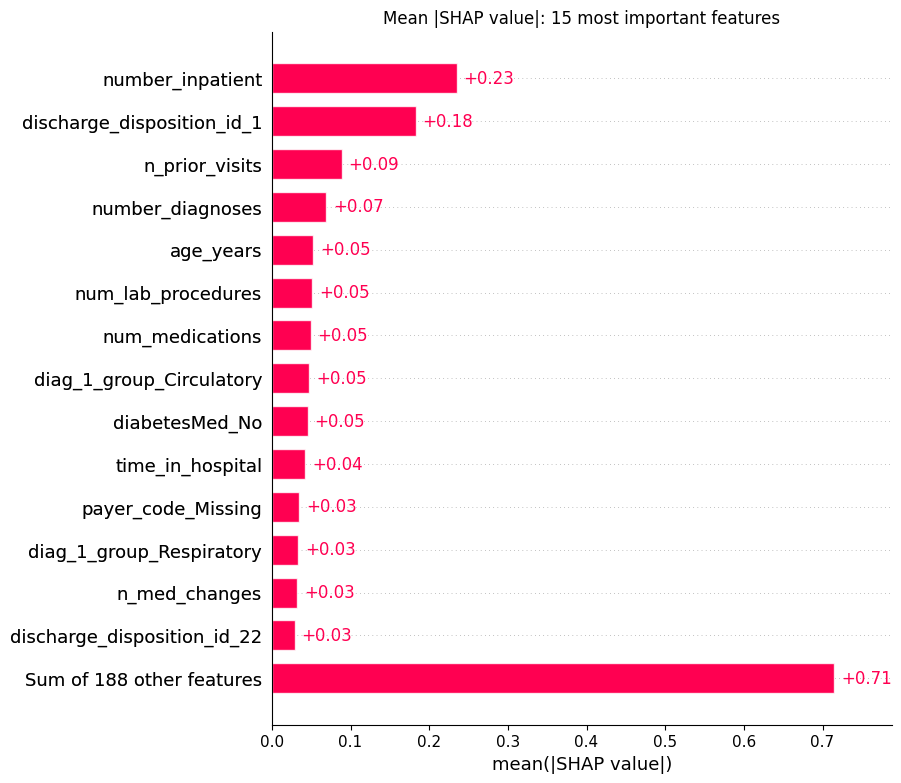

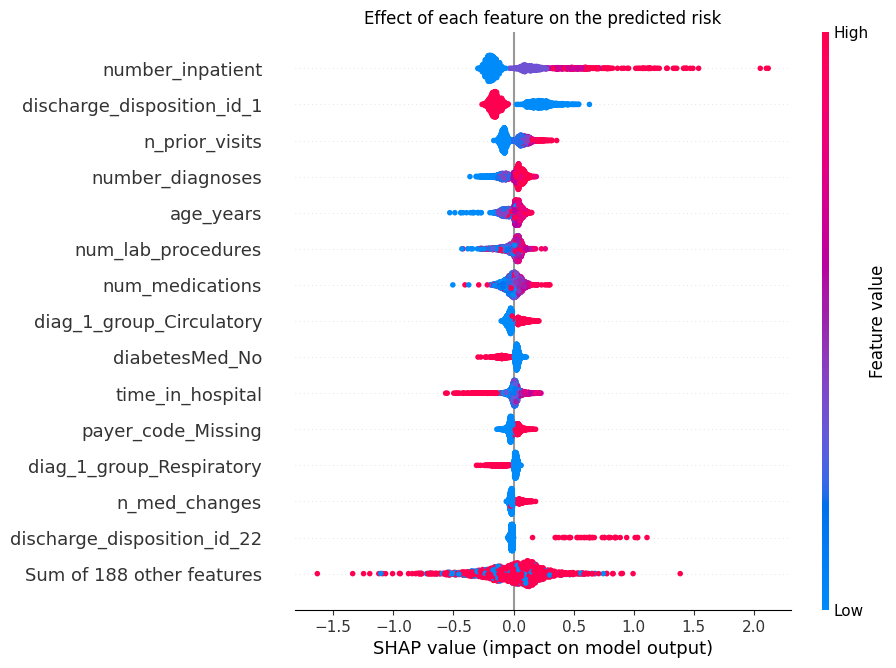

In [ ]:
# Global importance: mean |SHAP value| per column.
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Mean |SHAP value|: 15 most important features")
plt.show()

# Beeswarm: one dot per stay; colour = feature value (red = high); x = effect on the risk.
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Effect of each feature on the predicted risk")
plt.show()

- `number_inpatient` is by far the strongest: more past stays = higher risk. `n_prior_visits` (our feature) is third.
- Going home (`discharge_disposition_id_1`) lowers the risk; a transfer to rehab (code 22) raises it.
- More diagnoses, older age and more medications raise the risk.
- Circulatory diagnosis: a bit higher risk; respiratory: lower.
- `payer_code_Missing` raises the risk, probably a data-recording effect to monitor.

This makes business sense: frequent visitors, dependent and complex patients come back more often. No top feature is known only after discharge (no leakage). SHAP explains the model, not the causes (Session 8).

Two limits of these plots:
- one categorical variable is split into many one-hot columns, so we also sum the SHAP values per original variable;
- we compare with **permutation importance** (Session 8): shuffle one raw column and measure the PR-AUC drop.

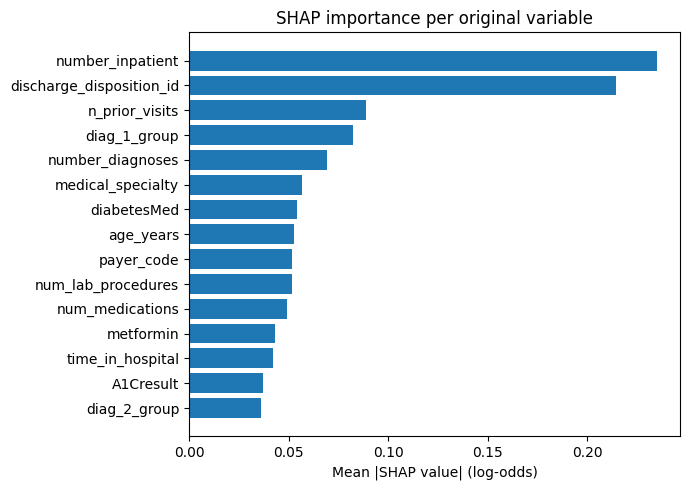

47 variables; the 3 most important ones carry 37% of the total importance


In [ ]:
# Sum the SHAP values of the one-hot columns of each original variable.
source_variables = numerical_features + categorical_features


def source_variable(column):
    matches = [v for v in source_variables if column == v or column.startswith(v + "_")]
    return max(matches, key=len)     # longest name: "glyburide.metformin" before "glyburide".


column_to_variable = pd.Series({c: source_variable(c) for c in feature_names})
shap_by_variable = pd.DataFrame(shap_values.values, columns=feature_names).T.groupby(column_to_variable).sum().T
shap_importance = shap_by_variable.abs().mean().sort_values(ascending=False)

top = shap_importance.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.title("SHAP importance per original variable")
plt.tight_layout()
plt.show()
print(f"{len(shap_importance)} variables; the 3 most important ones carry "
      f"{shap_importance.head(3).sum() / shap_importance.sum():.0%} of the total importance")

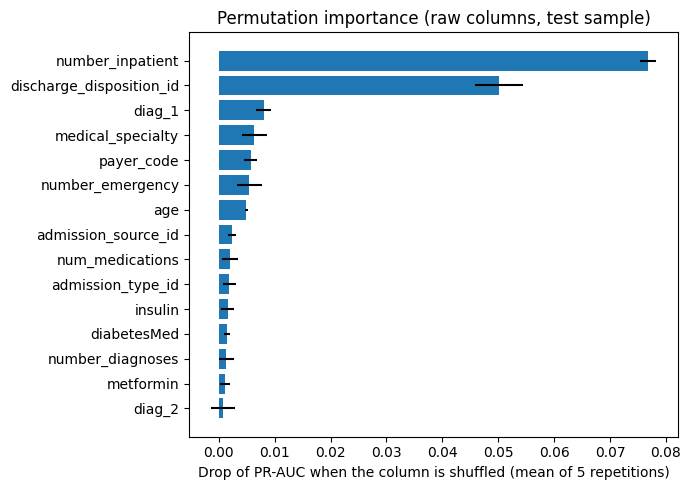

In [ ]:
from sklearn.inspection import permutation_importance

# Shuffle each raw column 5 times (8,000 test stays) and measure the PR-AUC drop.
perm_sample = X_test.sample(8000, random_state=RANDOM_STATE)
perm = permutation_importance(final_pipeline, perm_sample, y_test.loc[perm_sample.index],
                              scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE)
perm_importance = pd.Series(perm.importances_mean, index=perm_sample.columns).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=perm_sample.columns)[perm_importance.index]

top = perm_importance.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, xerr=perm_std[top.index].values)
plt.xlabel("Drop of PR-AUC when the column is shuffled (mean of 5 repetitions)")
plt.title("Permutation importance (raw columns, test sample)")
plt.tight_layout()
plt.show()

- `number_inpatient` and `discharge_disposition_id` are top 2 in both methods: robust.
- Grouped per variable, `diag_1_group` (4th) and `medical_specialty` (6th) move up.
- `number_diagnoses` is 5th for SHAP but ≈ 0 in permutation: correlated columns can replace it.
- `number_emergency`, `age` and `diag_1` show up in permutation because they feed our new features.
- After the top 5, drops are tiny (< 0.01) and their order is not reliable.

Permutation importance uses a test sample, but only to explain the model, not to make a choice.

Below, the shape of the effect of four numerical variables (black line = mean SHAP value).

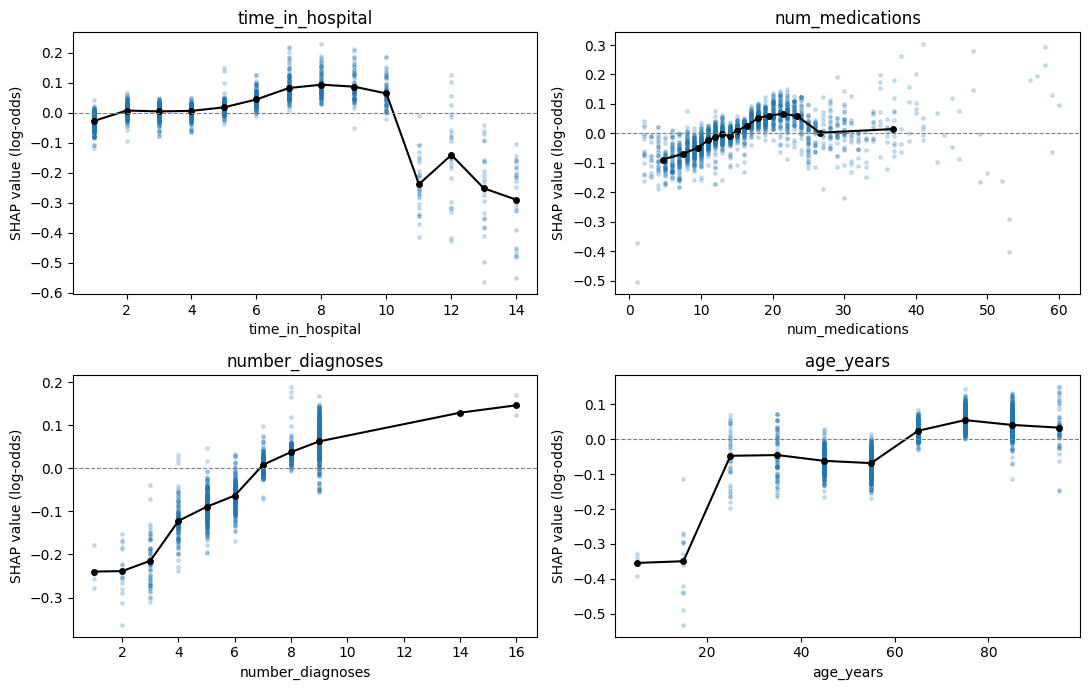

In [ ]:
X_sample_fe = add_features(X_test_sample)  # same stays, original units

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["time_in_hospital", "num_medications", "number_diagnoses", "age_years"]):
    x = X_sample_fe[col].values.astype(float)
    contribution = shap_values.values[:, feature_names.index(col)]
    # Black line = mean SHAP value per value (or per bin if more than 20 values).
    key = x if len(np.unique(x)) <= 20 else pd.qcut(x, 15, duplicates="drop")
    mean_by_value = pd.DataFrame({"x": x, "shap": contribution}).groupby(key, observed=True)[["x", "shap"]].mean()
    ax.scatter(x, contribution, s=6, alpha=0.2)
    ax.plot(mean_by_value["x"], mean_by_value["shap"], "k-o", markersize=4)
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set(title=col, xlabel=col, ylabel="SHAP value (log-odds)")
plt.tight_layout()
plt.show()

- `time_in_hospital`: risk rises up to 8–10 days, then drops for 11+ days.
- `num_medications`: rises up to 20–25, then back to about 0.
- `number_diagnoses`: rises steadily.
- `age_years`: much lower under 20, slightly higher above 60.

Surprise: in the EDA, long stays still had a high readmission rate (12.7% at 14 days), but SHAP gives them a negative effect. SHAP measures the effect *given the other features* (long stays already have many diagnoses and medications), while the EDA looks at one variable alone.

Local explanations for three test patients: a high-risk readmitted one, a missed readmission, and a low-risk one.

High risk, really readmitted: predicted score 0.92 (threshold 0.54), really readmitted = 1
{'age_years': 25, 'number_inpatient': 11, 'number_emergency': 3, 'n_prior_visits': 16, 'discharge_disposition_id': '1', 'time_in_hospital': 7, 'diag_1_group': 'Other'}


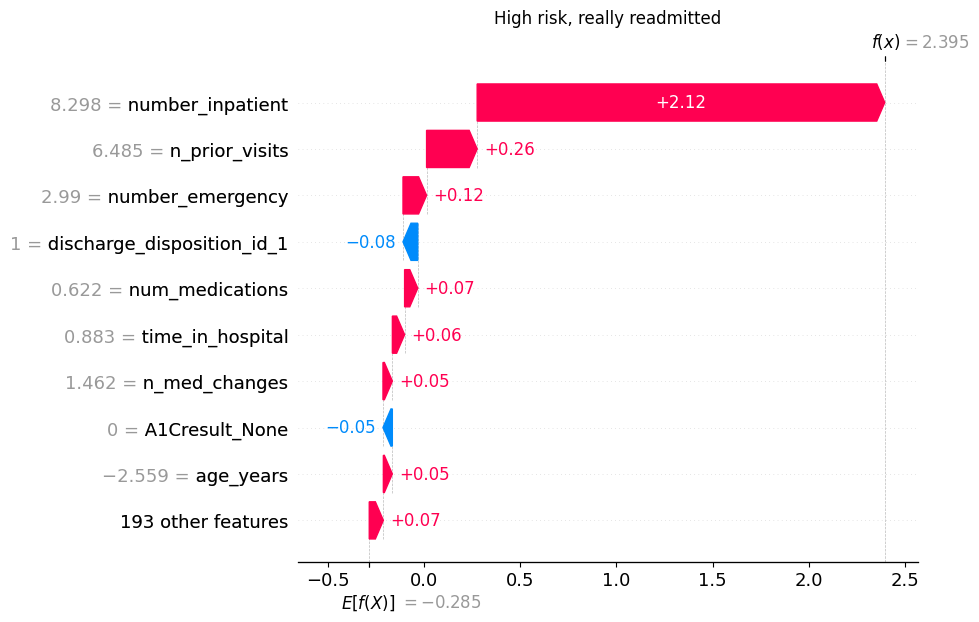

Missed readmission (false negative): predicted score 0.14 (threshold 0.54), really readmitted = 1
{'age_years': 35, 'number_inpatient': 0, 'number_emergency': 0, 'n_prior_visits': 0, 'discharge_disposition_id': '1', 'time_in_hospital': 12, 'diag_1_group': 'Genitourinary'}


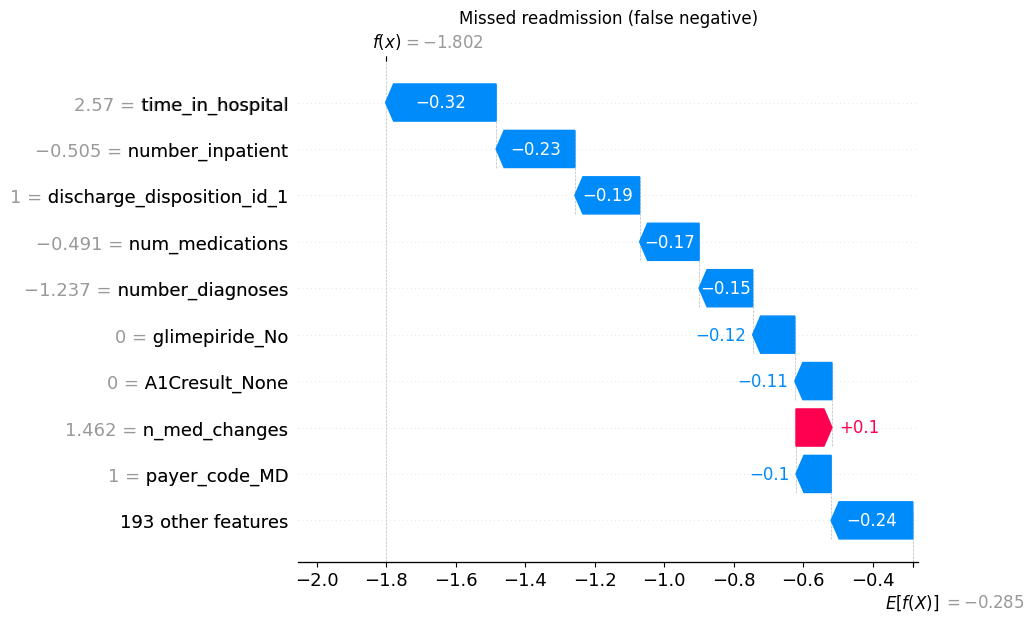

Low risk, not readmitted: predicted score 0.06 (threshold 0.54), really readmitted = 0
{'age_years': 55, 'number_inpatient': 0, 'number_emergency': 0, 'n_prior_visits': 0, 'discharge_disposition_id': '6', 'time_in_hospital': 3, 'diag_1_group': 'Musculoskeletal'}


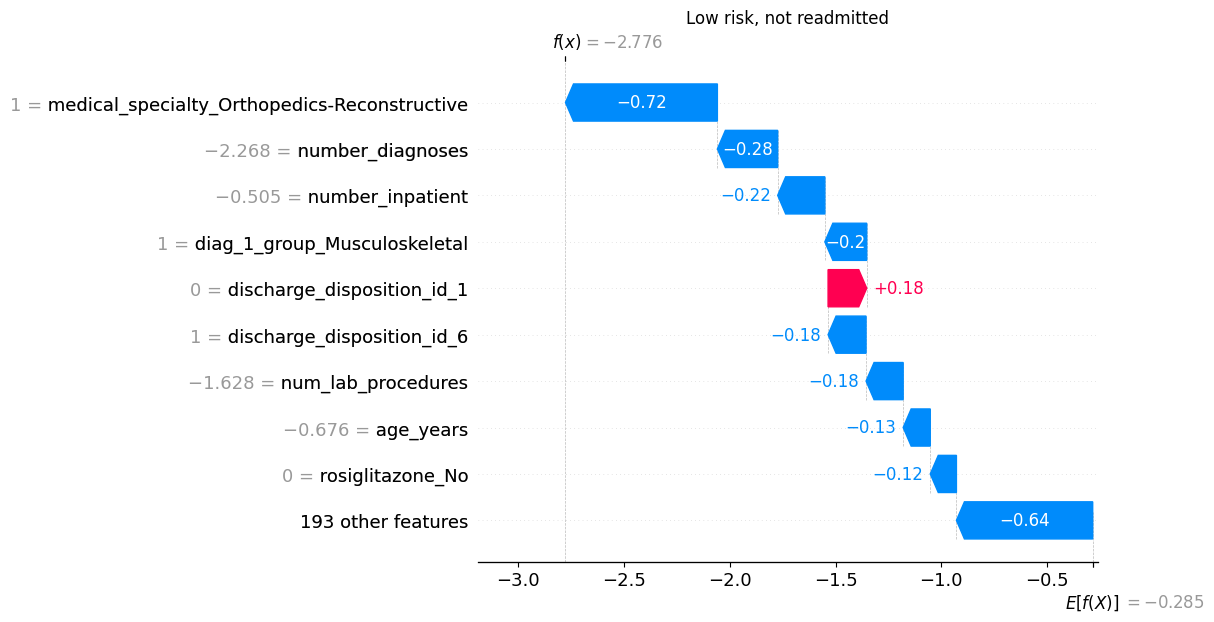

In [ ]:
sample_proba = final_pipeline.predict_proba(X_test_sample)[:, 1]
sample_y = y_test.loc[X_test_sample.index].values

# The three stays to explain.
examples = {
    "High risk, really readmitted": np.argmax(np.where(sample_y == 1, sample_proba, -1)),
    "Missed readmission (false negative)": np.argmin(np.where(sample_y == 1, sample_proba, 2)),
    "Low risk, not readmitted": np.argmin(np.where(sample_y == 0, sample_proba, 2)),
}

for title, i in examples.items():
    print(f"{title}: predicted score {sample_proba[i]:.2f} (threshold {threshold:.2f}), "
          f"really readmitted = {sample_y[i]}")
    print(add_features(X_test_sample.iloc[[i]]).iloc[0][["age_years", "number_inpatient", "number_emergency", "n_prior_visits",
                                 "discharge_disposition_id", "time_in_hospital", "diag_1_group"]].to_dict())
    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(title)
    plt.show()

*(Numerical values in the plots are standardised: `number_inpatient` = −0.5 means no past stay.)*

- **Score 0.92, readmitted**: 25 years old, 11 past stays and 3 emergency visits. `number_inpatient` alone adds +2.12. Clear "frequent flyer".
- **Score 0.14, missed**: 35 years old, no past visit, 12-day stay, sent home. Everything pushes the score down (long stay −0.32). The reason for this readmission is probably not in the data.
- **Score 0.06, not readmitted**: 55 years old, no past visit, 3-day stay, orthopaedic specialty (−0.72), few diagnoses (−0.28).

# Calibration Diagnostics

A model is calibrated if, among patients with a score of 0.3, about 30% are really readmitted (Session 7). On the test set we use:
- a **reliability curve** (10 groups of ≈ 1,970 stays) with a histogram of the scores. Below the diagonal = risk over-estimated; at high scores this is over-confidence;
- the **Brier score** (0 = perfect; always predicting the base rate gives 0.0987);
- the **ECE** (mean gap between score and real rate, 0 = perfect).

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


# ECE: 10 groups of the same size, weighted mean of |real rate - mean score|.
def expected_calibration_error(y_true, probability, n_bins=10):
    table = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(probability, dtype=float)})
    table["bin"] = pd.qcut(table["p"], q=n_bins, labels=False, duplicates="drop")
    summary = table.groupby("bin").agg(count=("y", "size"), observed=("y", "mean"), predicted=("p", "mean"))
    return float((summary["count"] / len(table) * (summary["observed"] - summary["predicted"]).abs()).sum())


def calibration_report(y_true, proba):
    return {"mean predicted score": proba.mean(), "observed rate": np.mean(y_true),
            "Brier score": brier_score_loss(y_true, proba), "ECE": expected_calibration_error(y_true, proba)}


# Reference: always predict the train base rate.
print(f"Reference Brier score (always predicting the base rate): "
      f"{brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f}")
pd.DataFrame({"LightGBM (class weights)": calibration_report(y_test, test_proba)}).T.round(4)

Reference Brier score (always predicting the base rate): 0.0987


,mean predicted score,observed rate,Brier score,ECE
LightGBM (class weights),0.4338,0.111,0.2051,0.3228


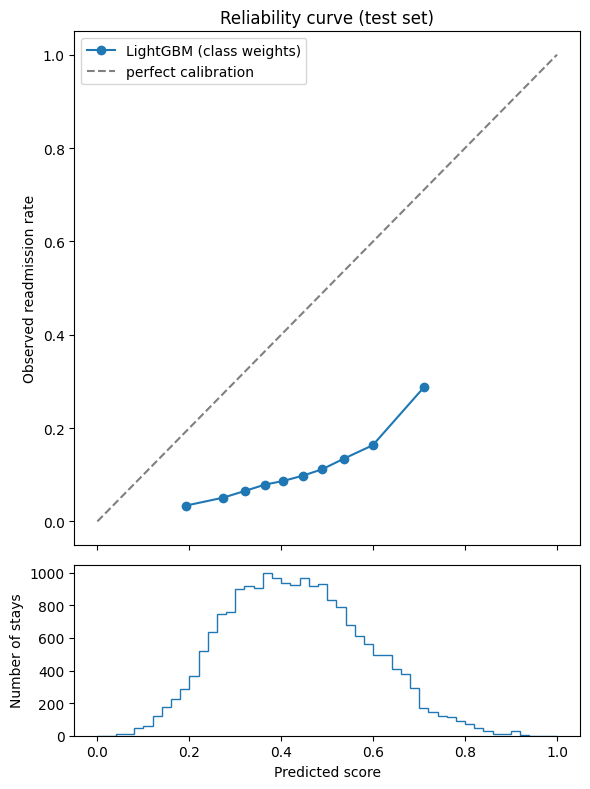

In [ ]:
# Reliability curve (top) and histogram of the scores (bottom), test set.
def plot_reliability(probas):
    fig, (ax_curve, ax_hist) = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                                            gridspec_kw={"height_ratios": [3, 1]})
    for name, p in probas.items():
        observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
        ax_curve.plot(predicted, observed, marker="o", label=name)
        ax_hist.hist(p, bins=50, range=(0, 1), histtype="step", label=name)
    ax_curve.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
    ax_curve.set(ylabel="Observed readmission rate", title="Reliability curve (test set)")
    ax_curve.legend()
    ax_hist.set(xlabel="Predicted score", ylabel="Number of stays")
    plt.tight_layout()
    plt.show()


plot_reliability({"LightGBM (class weights)": test_proba})

The raw scores are badly calibrated:
- mean score 0.434 vs 11.1% real readmissions; the histogram is centred around 0.4;
- the curve is below the diagonal everywhere (score ≈ 0.7 → only 29% readmitted): the model is **over-confident** and over-estimates the risk at every level;
- Brier 0.2051 (worse than the base rate, 0.0987), ECE 0.323.

This comes from the class weights (Session 6). The ranking and the threshold are fine, but we **cannot trust the raw scores as probabilities**.

We **recalibrate** the scores (Session 7) with two methods:
- **Platt scaling**: a sigmoid with 2 parameters; keeps the ranking.
- **Isotonic regression**: an increasing step function; more flexible, but can over-fit and creates ties.

The choice is made on the train set, not on the test set: we learn each method on 4 folds of the out-of-fold scores and evaluate it on the 5th. We keep isotonic only if it is clearly better; otherwise Platt (simpler). The test set is only used to check.

In [ ]:
from sklearn.isotonic import IsotonicRegression


def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


# Platt scaling = logistic regression on the logit of the score (large C = no penalty).
def fit_platt(scores, y):
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(scores).reshape(-1, 1), y)


# Returns the calibration function g learned on (scores, labels).
def fit_calibrator(method, scores, y):
    if method == "isotonic":
        iso = IsotonicRegression(out_of_bounds="clip").fit(scores, y)
        return iso.predict
    platt_model = fit_platt(scores, y)
    return lambda s: platt_model.predict_proba(logit(np.asarray(s)).reshape(-1, 1))[:, 1]


# Compare the two methods with CV on the out-of-fold train scores (no test data).
y_train_arr = y_train.values
cal_rows = []
for k, (fit_idx, eval_idx) in enumerate(folds):
    for method in ["isotonic", "Platt"]:
        g = fit_calibrator(method, oof[fit_idx], y_train_arr[fit_idx])
        p = g(oof[eval_idx])
        cal_rows.append({"fold": k, "method": method,
                         "Brier": brier_score_loss(y_train_arr[eval_idx], p),
                         "ECE": expected_calibration_error(y_train_arr[eval_idx], p)})
cal_cv = pd.DataFrame(cal_rows)
display(cal_cv.groupby("method")[["Brier", "ECE"]].agg(["mean", "std"]).round(5))

# Rule: isotonic only if it is clearly better than Platt.
brier_iso = cal_cv.loc[cal_cv["method"] == "isotonic", "Brier"].values
brier_platt = cal_cv.loc[cal_cv["method"] == "Platt", "Brier"].values
diff = brier_iso - brier_platt
print(f"Brier(isotonic) - Brier(Platt), fold by fold: mean {diff.mean():+.5f}, std {diff.std():.5f}, "
      f"isotonic better in {(diff < 0).sum()}/5 folds")
chosen_method = "isotonic" if diff.mean() < -diff.std() else "Platt"
print("Chosen calibration method:", chosen_method)

Brier               ECE         
             mean      std     mean      std
method                                      
Platt     0.09632  0.00188  0.00747  0.00159
isotonic  0.09639  0.00183  0.00717  0.00096

Brier(isotonic) - Brier(Platt), fold by fold: mean +0.00007, std 0.00007, isotonic better in 1/5 folds
Chosen calibration method: Platt


,mean predicted score,observed rate,Brier score,ECE,PR-AUC,distinct scores
raw (class weights),0.4338,0.111,0.2051,0.3228,0.2349,19370.0
isotonic,0.1164,0.111,0.0934,0.0064,0.2281,78.0
Platt,0.1164,0.111,0.0933,0.0080,0.2349,18756.0


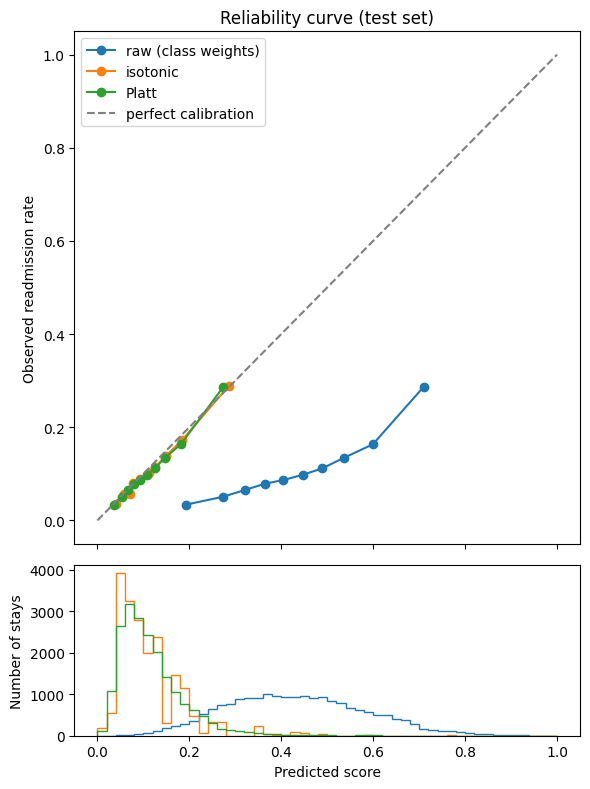

Platt scaling: slope 0.979, intercept -1.904


In [ ]:
# Learn both methods on all the out-of-fold scores, then check them on the test set.
calibrators = {method: fit_calibrator(method, oof, y_train_arr) for method in ["isotonic", "Platt"]}
scores_by_method = {"raw (class weights)": test_proba,
                    "isotonic": calibrators["isotonic"](test_proba),
                    "Platt": calibrators["Platt"](test_proba)}
display(pd.DataFrame({name: {**calibration_report(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                             "distinct scores": len(np.unique(p.round(6)))}
                      for name, p in scores_by_method.items()}).T.round(4))
plot_reliability(scores_by_method)

# Platt: calibrated logit = slope * logit(raw score) + intercept.
platt = fit_platt(oof, y_train_arr)
print(f"Platt scaling: slope {platt.coef_[0, 0]:.3f}, intercept {platt.intercept_[0]:.3f}")

# We keep the chosen method from now on.
calibrate = calibrators[chosen_method]
test_proba_calibrated = calibrate(test_proba)

**On the train folds:** Brier 0.09632 (Platt) vs 0.09639 (isotonic); isotonic is better in only 1 fold out of 5. So we keep **Platt scaling**.

**On the test set**, the choice is confirmed:
- both methods bring the mean score (11.6%) close to the real rate (11.1%), and the curves follow the diagonal;
- Brier 0.2051 → 0.0933 (Platt), better than the base rate; ECE 0.323 → 0.008;
- Platt keeps the ranking (PR-AUC 0.235); isotonic has only 78 distinct scores and loses a little (0.228).

Platt slope = 0.979 (≈ 1), intercept = −1.904: the correction is almost a simple shift of the log-odds, which is what class weights cause (ln 7.7 ≈ 2.0).

**Can we trust the probabilities?** The raw scores, no. The calibrated ones, yes, but they rarely go above 30% (see histogram), and calibration must be checked again over time (Session 7).

**The F1 threshold in terms of costs**

With calibrated probabilities, flagging is worth it if `p > 1 / (1 + r)`, where `r` = cost of a missed readmission / cost of a useless follow-up (Session 7). So a threshold `t` means `r = (1 − t) / t`.

In [ ]:
# Cost ratio hidden in the F1 threshold.
t = float(calibrate(np.array([threshold]))[0])
print(f"F1 threshold {threshold:.3f} = calibrated probability {t:.3f} ({chosen_method}) -> "
      f"a missed readmission is treated as {(1 - t) / t:.1f} times as costly as an unnecessary follow-up")

# Cost per 1,000 test stays (1 per false alarm, r per missed readmission).
y_t = np.asarray(y_test)
rows = {}
for ratio in [1, 2, 5, 10, 20]:
    strategies = {"flag nobody": np.zeros(len(y_t), dtype=bool),
                  "flag everybody": np.ones(len(y_t), dtype=bool),
                  "F1 threshold": test_proba >= threshold,
                  "cost-based threshold 1/(1+r)": test_proba_calibrated >= 1 / (1 + ratio)}
    row = {name: 1000 * ((f & (y_t == 0)).sum() + ratio * (~f & (y_t == 1)).sum()) / len(y_t)
           for name, f in strategies.items()}
    row["% flagged by the cost-based rule"] = 100 * strategies["cost-based threshold 1/(1+r)"].mean()
    rows[f"r = {ratio}"] = row
display(pd.DataFrame(rows).T.round(1))

F1 threshold 0.542 = calibrated probability 0.150 (Platt) -> a missed readmission is treated as 5.7 times as costly as an unnecessary follow-up


,flag nobody,flag everybody,F1 threshold,cost-based threshold 1/(1+r),% flagged by the cost-based rule
r = 1,111.0,889.0,248.2,111.1,0.3
r = 2,221.9,889.0,309.3,216.9,1.7
r = 5,554.8,889.0,492.4,482.6,18.3
r = 10,1109.6,889.0,797.7,731.2,56.2
r = 20,2219.3,889.0,1408.4,863.9,89.7


Cost per 1,000 test stays (1 per false alarm, r per missed readmission; lower is better):
- The F1 threshold (0.542) = a calibrated risk of 15%, so it assumes r ≈ 5.7. At r = 5 it costs 492.4, close to the cost-based rule (482.6), and better than flagging nobody (554.8) or everybody (889.0).
- For r = 2, the best threshold is 33% and flags only 1.7% of the stays.
- For r = 20, the F1 threshold (1408.4) is worse than flagging everybody (889.0); the cost-based rule (863.9) flags 89.7% of the stays.

The real costs are unknown, so this is only a sensitivity analysis.

# Fairness & Bias Audit

We audit `race`. The model does not use it, but other features can be correlated with it (Session 9).

Groups: Caucasian (75.2% of the test stays), African American (18.1%), and "Other / unknown" (the small groups merged, 126 readmitted stays).

Metrics per group (test set, global threshold), Session 9:
- **selection rate** → demographic parity;
- **TPR (recall)** → equal opportunity;
- **FPR** (with TPR) → equalised odds;
- **precision** → predictive parity;
- **disparate impact ratio** (min / max selection rate, alarm below 0.8).

These definitions cannot all hold when base rates differ, so we choose one first. The costly error is to miss a readmission, so our main criterion is **equal opportunity**.

In [ ]:
# Two large groups + "Other / unknown".
def race_group(race):
    return race.where(race.isin(["Caucasian", "AfricanAmerican"]), "Other / unknown")


group_train, group_test = race_group(race_train), race_group(race_test)
print(group_test.value_counts())


# Fairness metrics per group.
def fairness_table(y_true, y_pred, groups):
    rows = {}
    for g in sorted(groups.unique()):
        m = (groups == g).values
        yt, yp = np.asarray(y_true)[m], y_pred[m]
        tpr = yp[yt == 1].mean()
        rows[g] = {"n_stays": m.sum(), "n_readmitted": (yt == 1).sum(), "readmission rate": yt.mean(),
                   "selection rate": yp.mean(), "TPR (recall)": tpr,
                   "TPR std (approx.)": np.sqrt(tpr * (1 - tpr) / (yt == 1).sum()),
                   "FPR": yp[yt == 0].mean(), "precision": yt[yp == 1].mean()}
    return pd.DataFrame(rows).T


# Gap = max - min over the groups.
def fairness_gaps(table):
    return {"demographic parity gap (selection rate)": table["selection rate"].max() - table["selection rate"].min(),
            "equal opportunity gap (TPR)": table["TPR (recall)"].max() - table["TPR (recall)"].min(),
            "FPR gap": table["FPR"].max() - table["FPR"].min()}


test_pred = (test_proba >= threshold).astype(int)
before = fairness_table(y_test, test_pred, group_test)
display(before.round(3))
pd.Series(fairness_gaps(before)).round(3).to_frame("gap (max - min, 3 groups)")

race
Caucasian          14825
AfricanAmerican     3578
Other / unknown     1315
Name: count, dtype: int64


,n_stays,n_readmitted,readmission rate,selection rate,TPR (recall),TPR std (approx.),FPR,precision
AfricanAmerican,3578.0,410.0,0.115,0.239,0.439,0.025,0.213,0.211
Caucasian,14825.0,1652.0,0.111,0.240,0.449,0.012,0.214,0.208
Other / unknown,1315.0,126.0,0.096,0.199,0.500,0.045,0.167,0.240


,"gap (max - min, 3 groups)"
demographic parity gap (selection rate),0.041
equal opportunity gap (TPR),0.061
FPR gap,0.046


In [ ]:
# Disparate impact ratio and predictive parity gap.
def extra_fairness_metrics(table):
    selection = table["selection rate"]
    large = selection[["Caucasian", "AfricanAmerican"]]
    return {"disparate impact ratio, all groups (min / max selection rate)": selection.min() / selection.max(),
            "disparate impact ratio, Caucasian vs African American": large.min() / large.max(),
            "predictive parity gap (precision, max - min)": table["precision"].max() - table["precision"].min()}


# Gaps between the two large groups only.
def pair_gaps(table, a="Caucasian", b="AfricanAmerican"):
    return {f"{metric} gap, Caucasian vs African American": abs(table.loc[a, metric] - table.loc[b, metric])
            for metric in ["selection rate", "TPR (recall)", "FPR", "precision"]}


pd.Series({**extra_fairness_metrics(before), **pair_gaps(before)}).round(3).to_frame("value")

,value
"disparate impact ratio, all groups (min / max selection rate)",0.830
"disparate impact ratio, Caucasian vs African American",0.996
"predictive parity gap (precision, max - min)",0.032
"selection rate gap, Caucasian vs African American",0.001
"TPR (recall) gap, Caucasian vs African American",0.010
"FPR gap, Caucasian vs African American",0.001
"precision gap, Caucasian vs African American",0.002


- **Caucasian vs African American**: very close on everything. Selection 24.0% vs 23.9%, recall 44.9% vs 43.9%, FPR 21.4% vs 21.3%, precision 20.8% vs 21.1%.
- **Equal opportunity**: the 1.0-point recall gap is smaller than its uncertainty (std ≈ 2.5 points for African American patients).
- **Four-fifths rule**: 0.996 (two large groups), 0.830 (three groups), both above 0.8.
- The bigger gaps across the three groups (recall 6.1 points, FPR 4.6) come from the small "Other / unknown" group (recall std ≈ 4.5 points): mostly noise.

Being flagged gives a follow-up call (a benefit). The model looks fair between the two main groups.

**Mitigation: one threshold per group** (post-processing, Session 9). Each group gets the threshold that gives the same recall on the train set (out-of-fold scores). We then compare before/after on the test set.

Limit: it needs the patient's race at decision time (legal and ethical question).

In [ ]:
# Target recall = recall of the global threshold on the train set.
target_tpr = ((oof >= threshold)[y_train.values == 1]).mean()
print(f"Target TPR (train, global threshold): {target_tpr:.3f}")

# One threshold per group, chosen on the train set to reach this recall.
group_thresholds = {}
for g in group_train.unique():
    scores_pos = oof[(group_train == g).values & (y_train.values == 1)]
    group_thresholds[g] = np.quantile(scores_pos, 1 - target_tpr)
print("Thresholds per group:", {g: round(float(t), 3) for g, t in group_thresholds.items()})

# Apply them to the test set.
test_thresholds = group_test.map(group_thresholds).values
test_pred_fair = (test_proba >= test_thresholds).astype(int)
after = fairness_table(y_test, test_pred_fair, group_test)
display(after.round(3))

def performance(y_pred):
    return {"accuracy": accuracy_score(y_test, y_pred), "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred), "f1": f1_score(y_test, y_pred)}


def full_summary(table):
    return {**fairness_gaps(table), **extra_fairness_metrics(table), **pair_gaps(table)}


comparison_fairness = pd.DataFrame({
    "before (one threshold)": {**performance(test_pred), **full_summary(before)},
    "after (one threshold per group)": {**performance(test_pred_fair), **full_summary(after)},
})
comparison_fairness.round(3)

Target TPR (train, global threshold): 0.446
Thresholds per group: {'Caucasian': 0.541, 'AfricanAmerican': 0.555, 'Other / unknown': 0.526}


,n_stays,n_readmitted,readmission rate,selection rate,TPR (recall),TPR std (approx.),FPR,precision
AfricanAmerican,3578.0,410.0,0.115,0.219,0.415,0.024,0.194,0.217
Caucasian,14825.0,1652.0,0.111,0.243,0.451,0.012,0.217,0.206
Other / unknown,1315.0,126.0,0.096,0.230,0.540,0.044,0.197,0.225


,before (one threshold),after (one threshold per group)
accuracy,0.752,0.751
precision,0.211,0.209
recall,0.450,0.449
f1,0.287,0.286
demographic parity gap (selection rate),0.041,0.024
equal opportunity gap (TPR),0.061,0.125
FPR gap,0.046,0.023
"disparate impact ratio, all groups (min / max selection rate)",0.830,0.901
"disparate impact ratio, Caucasian vs African American",0.996,0.901
"predictive parity gap (precision, max - min)",0.032,0.019


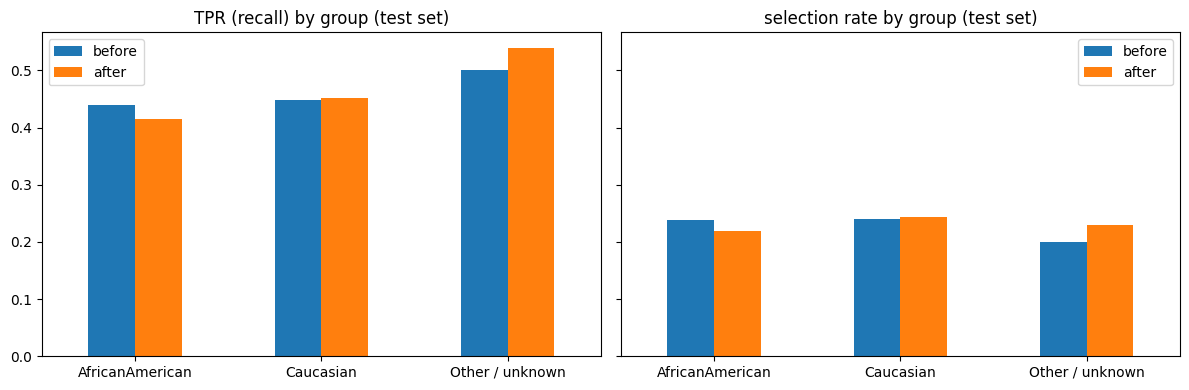

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ["TPR (recall)", "selection rate"]):
    pd.DataFrame({"before": before[metric], "after": after[metric]}).plot(kind="bar", ax=ax)
    ax.set_title(f"{metric} by group (test set)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Bootstrap by patient: change of the gaps (after - before), thresholds kept fixed.
group_names = sorted(group_test.unique())
groups_arr = group_test.values
changes = []
for idx in bootstrap_indices(patients_test, 500, RANDOM_STATE):
    yb, gb = y_arr[idx], groups_arr[idx]
    gaps = {}
    for label, pred in (("before", test_pred), ("after", test_pred_fair)):
        pb = pred[idx]
        tpr = [pb[(gb == g) & (yb == 1)].mean() for g in group_names]
        selection = [pb[gb == g].mean() for g in group_names]
        gaps[f"recall gap {label}"] = max(tpr) - min(tpr)
        gaps[f"selection gap {label}"] = max(selection) - min(selection)
    changes.append({"change of the recall gap": gaps["recall gap after"] - gaps["recall gap before"],
                    "change of the selection-rate gap": gaps["selection gap after"] - gaps["selection gap before"]})
changes = pd.DataFrame(changes)
display(pd.DataFrame({"mean": changes.mean(), "95% CI low": changes.quantile(0.025),
                      "95% CI high": changes.quantile(0.975), "share of resamples > 0": (changes > 0).mean()}).round(3))

,mean,95% CI low,95% CI high,share of resamples > 0
change of the recall gap,0.050,-0.024,0.095,0.946
change of the selection-rate gap,-0.015,-0.044,0.035,0.182


**Results on the test set:**
- Overall performance barely changes (F1 0.287 → 0.286). PR-AUC does not change (only the decision rule changes).
- Across the three groups, the selection and FPR gaps shrink (0.041 → 0.024, 0.046 → 0.023), only because "Other / unknown" is now flagged more.
- **Between the two large groups, all gaps get worse**: recall 1.0 → 3.6 points, selection 0.1 → 2.4 points (ratio 0.996 → 0.901), FPR 0.1 → 2.3 points.
- **Our main criterion gets worse**: recall gap 0.061 → 0.125.

The thresholds learned noise on the train set. The bootstrap shows the changes are not significant (both intervals contain 0).

**Decision: we keep one global threshold**, and recommend monitoring recall by group over time.

# Conclusion

- **Problem**: predict at discharge a readmission within 30 days (11.4% of the stays). Main metric: PR-AUC (average precision).
- **Split**: 80/20 by patient; the test set is used once for the final evaluation.
- **Features**: 3 new features + 9 diagnosis groups, inside the Pipeline. Gains within noise, kept because simple and leakage-free.
- **Imbalance**: class weights (undersampling and SMOTE not better) + threshold 0.542 chosen on out-of-fold predictions.
- **Models** (CV PR-AUC, start → tuned): Logistic Regression 0.216 → 0.216, Random Forest 0.220 → 0.220, LightGBM 0.230 → 0.234. 50 Optuna trials logged in MLflow.
- **Final model** (LightGBM, test): PR-AUC 0.235 (95% CI 0.213–0.258), ROC-AUC 0.682, recall 45.0%, precision 21.1%. Matches the CV estimate.
- **Explainability**: past stays, discharge destination and patient complexity drive the risk, which makes sense.
- **Calibration**: raw scores over-estimate the risk (Brier 0.205). Platt scaling, chosen on the train set, fixes it (Brier 0.093) without changing the ranking.
- **Fairness (race)**: no evidence of unequal opportunity (recall 44.9% vs 43.9%). Per-group thresholds made things worse, so we keep one threshold.
- **Limits**: moderate performance, test set from the same hospitals and years, threshold based on F1 and not on real costs.